#Umbrales normativos considerados

In [1]:
umbrales = {
    'IRI': {
        'Bueno':   (0.0, 1.8),
        'Regular': (1.8, 2.5),
        'Malo':    (2.5, float('inf'))
    },
    'JF': {  # Escalonamiento [mm]
        'Bueno':   (0.0, 10.0),
        'Regular': (10.0, 20.0),
        'Malo':    (20.0, float('inf'))
    },
    'LTE': {  # [%]  (más alto = mejor)
        'Malo':    (0.0,  50.0),
        'Regular': (50.0, 70.0),
        'Bueno':   (70.0, float('inf'))
    },
    'DEF': {  # Deflexión residual [mm]
        'Bueno':   (0.0,    0.050),
        'Regular': (0.050,  0.25),
        'Malo':    (0.25,  float('inf'))
    },
    'CF': {   # Fricción
        'Malo_Bajo': (0.00, 0.41),
        'Regular':   (0.41, 0.61),
        'Bueno':     (0.61, 0.90),
        'Malo_Alto': (0.90, float('inf'))
    },
    'TX': {   # Macrotextura
        'Malo':    (0.00, 0.75),
        'Regular': (0.75, 0.90),
        'Bueno':   (0.90, float('inf'))
    }
}


#Proceos Analítico Jerárquico

In [2]:
import numpy as np

# =============== AHP (PROCESO ANALÍTICO JERÁRQUICO) ====================

def ahp_weights(matrix):
    """Calcula pesos, CI y CR para una matriz AHP."""
    eigvals, eigvecs = np.linalg.eig(matrix)
    max_index = np.argmax(eigvals.real)
    max_eigval = eigvals[max_index].real
    weights = np.abs(eigvecs[:, max_index].real)
    weights = weights / weights.sum()

    n = matrix.shape[0]
    RI_dict = {1: 0.0, 2: 0.0, 3: 0.58, 4: 0.9, 5: 1.12, 6: 1.24, 7: 1.32, 8: 1.41, 9: 1.45, 10: 1.49} #ÍNDICE AL AZAR
    CI = (max_eigval - n) / (n - 1)
    RI = RI_dict.get(n, 0.58)
    CR = CI / RI if RI != 0 else 0

    return weights, CI, CR

def mostrar_pesos(nombre, nombres_elementos, matrix):
    """Resultados."""
    pesos, ci, cr = ahp_weights(matrix)
    print(f"\n📌 {nombre}:")
    for nombre_elemento, peso in zip(nombres_elementos, pesos):
        print(f"{nombre_elemento}: {peso:.4f}")
    print("CR:", round(cr, 4))
    if cr < 0.10:
        print("✅ Matriz consistente (CR < 0.10)")
    else:
        print("⚠️ Matriz inconsistente (CR >= 0.10).")
    return pesos

def mostrar_integridad(peso, nombre):
    """Subcriterios únicos."""
    print(f"\n📌 Subcriterio de {nombre}:")
    print(f"Peso: {peso}")
    print("✅ Solo un subcriterio, por lo que no hay matriz ni CR.")
    return np.array([peso])

# ==================== ESCALA FUNDAMENTAL DE SAATY ====================

# Escala Fundamental de Saaty para las comparaciones
ESCALA_SAATY = {
    "Igual": 1,
    "Entre igual y moderado": 2,
    "Moderado": 3,
    "Entre moderado y fuerte": 4,
    "Fuerte": 5,
    "Entre fuerte y muy fuerte": 6,
    "Muy fuerte": 7,
    "Entre muy fuerte y extremadamente fuerte": 8,
    "Extremadamente fuerte": 9
}

# ==================== CONFIGURACIÓN PRINCIPAL ====================

# 1. Criterios principales (orden: Seguridad, Operatividad, Integridad Estructural)
criterios_nombres = ['Seguridad', 'Operatividad', 'Integridad Estructural']
criterios_matrix = np.array([
    [1,   3,   6],  # Seguridad vs Operatividad vs Integridad
    [1/3, 1,   2],
    [1/6, 1/2, 1]
])

# 2. Subcriterios

# 2.1 Integridad estructural: LTE y DEF (Deflexión residual)
integridad_nombres = ['LTE', 'DEF']
integridad_matrix = np.array([
    [1, 1],   # LTE vs DEF
    [1, 1]
])

# 2.2 Seguridad: CF y TX
seguridad_nombres = ['CF', 'TX']
seguridad_matrix = np.array([
    [1, 1],   # CF y TX
    [1, 1]
])

# 2.3 Operatividad: IRI y JF
operatividad_nombres = ['IRI', 'JF']
operatividad_matrix = np.array([
    [1,   5],   # IRI vs JF
    [1/5, 1]
])

# 3. Alternativas (Bueno, Regular, Malo)
alternativas_nombres = ['Bueno', 'Regular', 'Malo']
alternativas_matrix = np.array([
    [1,   2,   6],  # Bueno vs Regular vs Malo
    [1/2, 1,   3],
    [1/6, 1/3, 1]
])

# ==================== EJECUCIÓN Y VISUALIZACIÓN ====================

print("="*60)
print("ANÁLISIS JERÁRQUICO (AHP) PARA PAVIMENTOS RÍGIDOS")
print("="*60)

# Nivel 1: Criterios principales
pesos_criterios = mostrar_pesos("Criterios principales", criterios_nombres, criterios_matrix)

# Nivel 2: Subcriterios
pesos_seguridad = mostrar_pesos("Subcriterios de Seguridad", seguridad_nombres, seguridad_matrix)
pesos_operatividad = mostrar_pesos("Subcriterios de Operatividad", operatividad_nombres, operatividad_matrix)
pesos_integridad = mostrar_pesos("Subcriterios de Integridad estructural", integridad_nombres, integridad_matrix)

# Nivel 3: Alternativas para cada indicador
print("\n" + "="*60)
print("EVALUACIÓN DE ALTERNATIVAS POR SUBCRITERIO")
print("="*60)

# Seguridad
pesos_cf   = mostrar_pesos("Alternativas para CF", alternativas_nombres, alternativas_matrix)
pesos_tx   = mostrar_pesos("Alternativas para TX", alternativas_nombres, alternativas_matrix)

# Operatividad
pesos_iri  = mostrar_pesos("Alternativas para IRI", alternativas_nombres, alternativas_matrix)
pesos_jf   = mostrar_pesos("Alternativas para JF", alternativas_nombres, alternativas_matrix)

# Integridad Estructural
pesos_lte  = mostrar_pesos("Alternativas para LTE", alternativas_nombres, alternativas_matrix)
pesos_def  = mostrar_pesos("Alternativas para DEF", alternativas_nombres, alternativas_matrix)

# Peso global de las alternativas promedio
pesos_alternativas = mostrar_pesos("Alternativas (matriz base B-R-M)", alternativas_nombres, alternativas_matrix)

# ==================== CÁLCULO DE PESOS GLOBALES ====================

print("\n" + "="*60)
print("PESOS GLOBALES FINALES")
print("="*60)

pesos_globales = {
    'CF' : pesos_criterios[0] * pesos_seguridad[0],
    'TX' : pesos_criterios[0] * pesos_seguridad[1],
    'IRI': pesos_criterios[1] * pesos_operatividad[0],
    'JF' : pesos_criterios[1] * pesos_operatividad[1],
    'LTE': pesos_criterios[2] * pesos_integridad[0],
    'DEF': pesos_criterios[2] * pesos_integridad[1],
}

for param, peso in pesos_globales.items():
    print(f"{param}: {peso:.4f}")


ANÁLISIS JERÁRQUICO (AHP) PARA PAVIMENTOS RÍGIDOS

📌 Criterios principales:
Seguridad: 0.6667
Operatividad: 0.2222
Integridad Estructural: 0.1111
CR: 0.0
✅ Matriz consistente (CR < 0.10)

📌 Subcriterios de Seguridad:
CF: 0.5000
TX: 0.5000
CR: 0
✅ Matriz consistente (CR < 0.10)

📌 Subcriterios de Operatividad:
IRI: 0.8333
JF: 0.1667
CR: 0
✅ Matriz consistente (CR < 0.10)

📌 Subcriterios de Integridad estructural:
LTE: 0.5000
DEF: 0.5000
CR: 0
✅ Matriz consistente (CR < 0.10)

EVALUACIÓN DE ALTERNATIVAS POR SUBCRITERIO

📌 Alternativas para CF:
Bueno: 0.6000
Regular: 0.3000
Malo: 0.1000
CR: -0.0
✅ Matriz consistente (CR < 0.10)

📌 Alternativas para TX:
Bueno: 0.6000
Regular: 0.3000
Malo: 0.1000
CR: -0.0
✅ Matriz consistente (CR < 0.10)

📌 Alternativas para IRI:
Bueno: 0.6000
Regular: 0.3000
Malo: 0.1000
CR: -0.0
✅ Matriz consistente (CR < 0.10)

📌 Alternativas para JF:
Bueno: 0.6000
Regular: 0.3000
Malo: 0.1000
CR: -0.0
✅ Matriz consistente (CR < 0.10)

📌 Alternativas para LTE:
Bueno: 0.6

#DATOS DE AUSCULTACIÓN


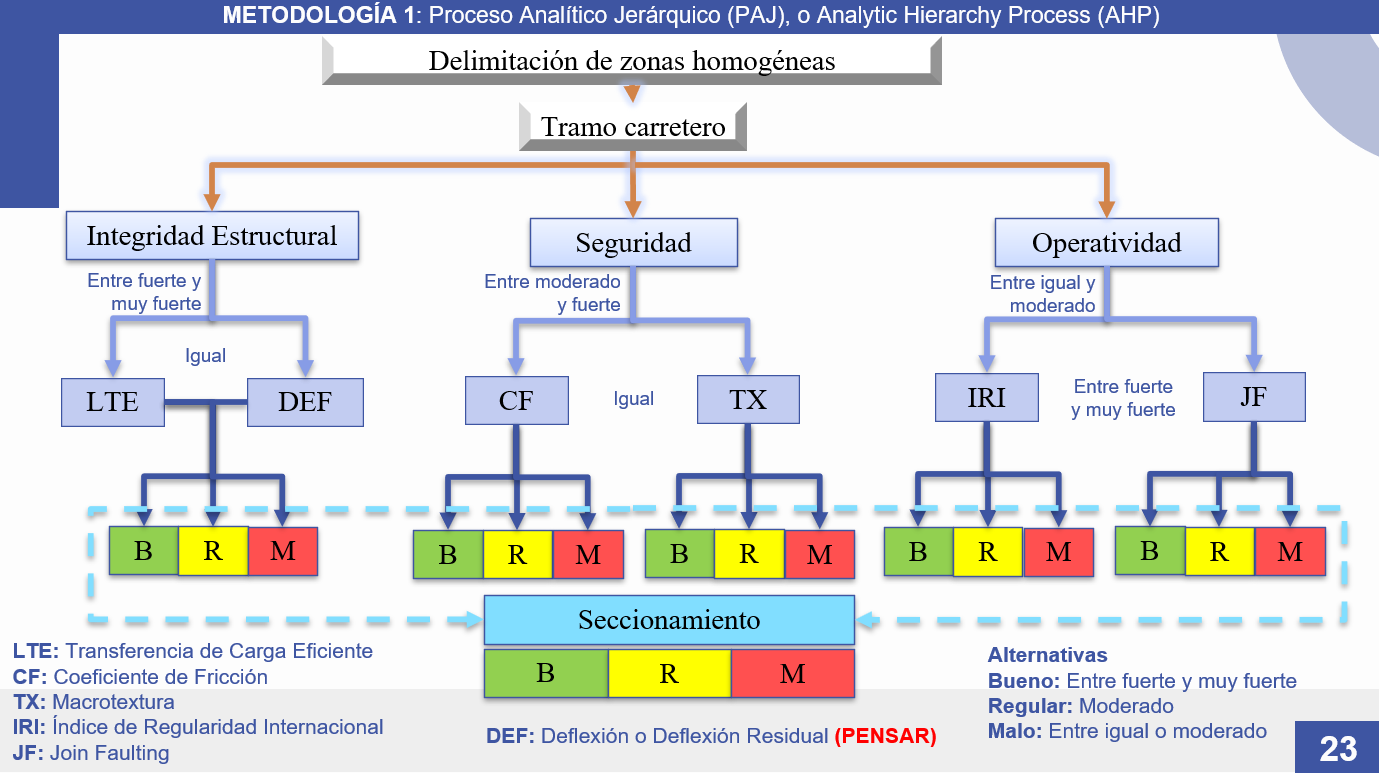

In [3]:
import numpy as np
import pandas as pd
df = pd.read_excel("Experimento.xlsx", sheet_name="Representativa")
df.columns

# Parámetros globales del tramo
longitud_total_km = 5
longitud_segmento_metros = 300
longitud_total_m = longitud_total_km * 1000
num_segments = int(np.ceil(longitud_total_m / longitud_segmento_metros))

# Generamos datos para cada cuerpo (sentido)

df_ida = df.copy()
df_vuelta = df.copy()

df_ida["Sentido"] = "IDA"
df_vuelta["Sentido"] = "VUELTA"

df_tramo_ida = df_ida.copy()
df_tramo_vuelta = df_vuelta.copy()

Cadenamiento a decimal

In [4]:
import pandas as pd
import numpy as np

def km_estacado_a_km(x):
    """
    Convierte formato 'A+BBB' a kilómetros float:
    '0+300' -> 0.300
    '12+450' -> 12.450
    """
    if pd.isna(x):
        return np.nan
    s = str(x).strip()
    if "+" not in s:
        # Si ya viene numérico o como texto numérico
        try:
            return float(s)
        except:
            return np.nan
    a, b = s.split("+", 1)
    a = a.strip()
    b = b.strip()
    # Quitar posibles ceros o espacios
    try:
        return float(a) + float(b)/1000.0
    except:
        return np.nan

# Convertir KM_Inicio y KM_Fin
df_tramo_ida["KM_Inicio"] = df_tramo_ida["KM_Inicio"].apply(km_estacado_a_km)
df_tramo_ida["KM_Fin"]    = df_tramo_ida["KM_Fin"].apply(km_estacado_a_km)

# Convertir indicadores a numérico
cols_ind = ['IRI','JF','LTE','DEF','CF','TX']
df_tramo_ida[cols_ind] = df_tramo_ida[cols_ind].apply(pd.to_numeric, errors='coerce')


##Gráficas

<>:39: SyntaxWarning: invalid escape sequence '\m'
<>:39: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_1831/4057882494.py:39: SyntaxWarning: invalid escape sequence '\m'
  "DEF": "Deflection ($\mu m$)"


Imagen compuesta guardada en: graficas_resultados/Full_Profile_Representative.png


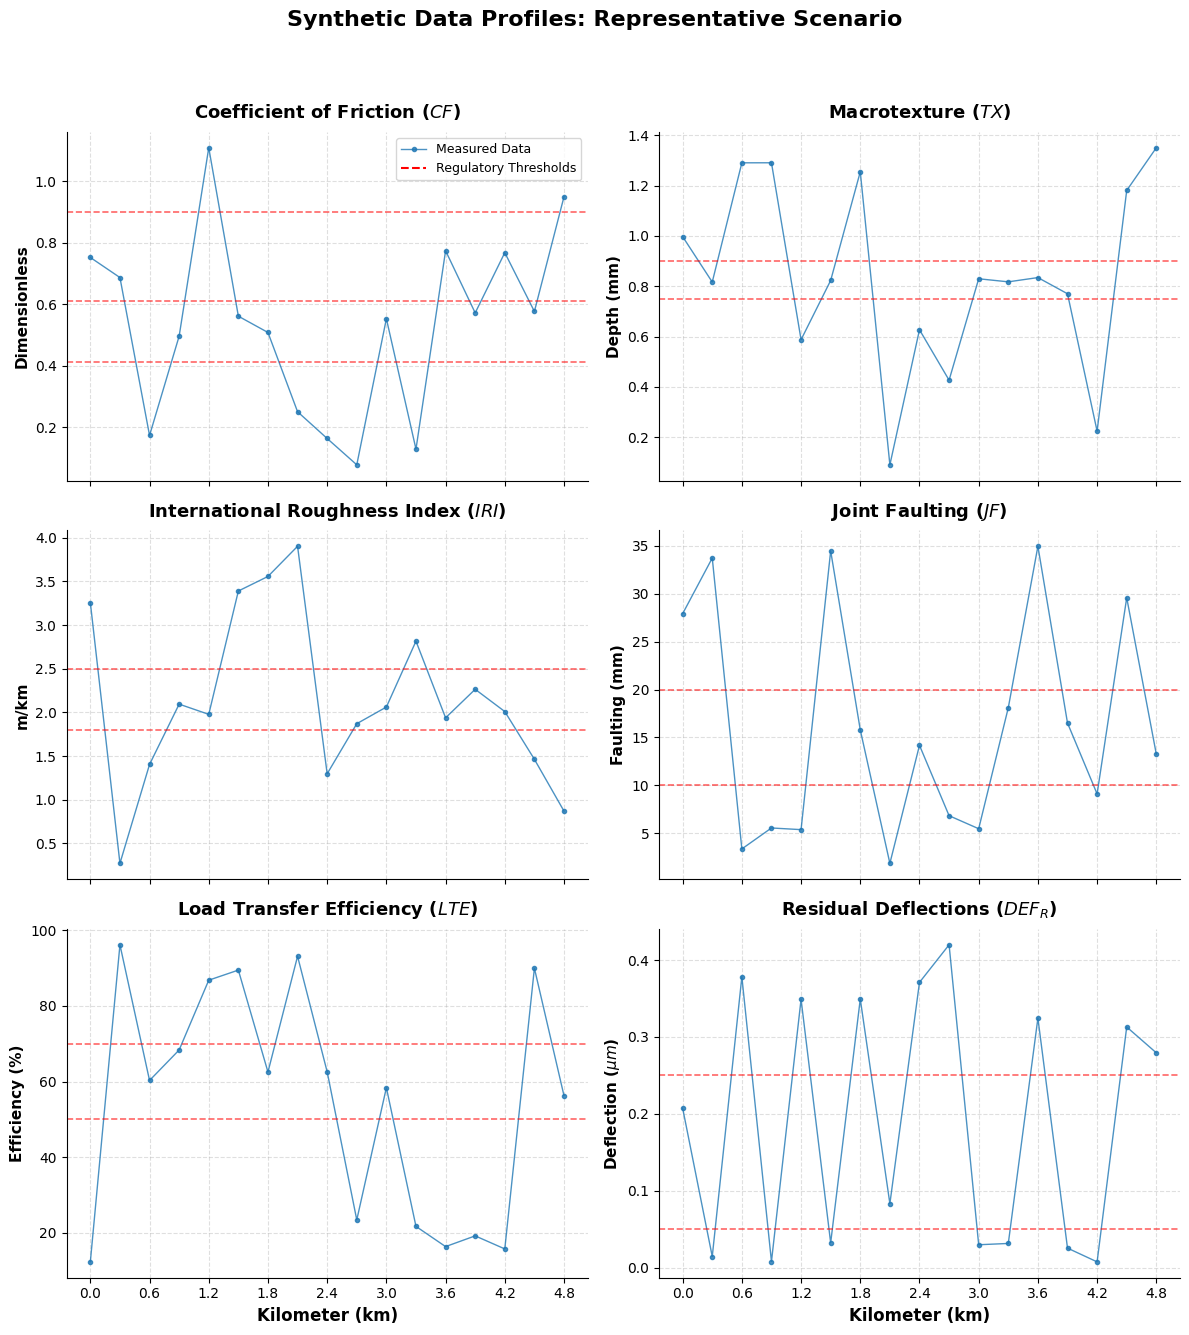

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import os

def graficar_paneles_cientificos(df, variables_list, umbrales_dict, nombre_escenario="Representative", carpeta_salida="graficas_resultados"):
    """
    Genera una sola imagen con 6 paneles (3x2) con etiquetas técnicas y unidades.
    """
    # 1. Crear carpeta si no existe
    if not os.path.exists(carpeta_salida):
        os.makedirs(carpeta_salida)

    # 2. Configuración de la grilla (3 filas, 2 columnas)
    fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(12, 14), sharex=True)
    axes_flat = axes.flatten()

    # Título principal de la figura completa
    fig.suptitle(f"Synthetic Data Profiles: {nombre_escenario} Scenario",
                 fontsize=16, fontweight='bold', y=0.98)

    # 3. Diccionarios de mapeo técnico para MDPI
    nombres_titulos = {
        "CF": "Coefficient of Friction ($CF$)",
        "TX": "Macrotexture ($TX$)",
        "IRI": "International Roughness Index ($IRI$)",
        "JF": "Joint Faulting ($JF$)",
        "LTE": "Load Transfer Efficiency ($LTE$)",
        "DEF": "Residual Deflections ($DEF_R$)"
    }

    unidades_y = {
        "CF": "Dimensionless",
        "TX": "Depth (mm)",
        "IRI": "m/km",
        "JF": "Faulting (mm)",
        "LTE": "Efficiency (%)",
        "DEF": "Deflection ($\mu m$)"
    }

    # 4. Bucle de graficación
    for i, var in enumerate(variables_list):
        ax = axes_flat[i]

        # Graficar datos medidos
        ax.plot(df["KM_Inicio"], df[var], marker="o", markersize=3,
                linewidth=1, label="Measured Data", color="#1f77b4", alpha=0.8)

        # Graficar umbrales regulatorios (si existen)
        if var in umbrales_dict:
            limites = umbrales_dict[var]
            # Extraer valores únicos de los umbrales para evitar líneas duplicadas
            valores_y = sorted({v for l in limites.values() for v in l if v not in (0.0, float('inf'))})

            for y_val in valores_y:
                ax.axhline(y=y_val, linestyle="--", color="red", alpha=0.6, linewidth=1.2)

            # Añadir entrada de leyenda para umbrales solo si hay líneas
            if valores_y:
                ax.plot([], [], linestyle="--", color="red", label="Regulatory Thresholds")

        # --- Formateo de cada Subplot ---
        ax.set_title(nombres_titulos.get(var, var), fontsize=13, fontweight='bold', pad=10)
        ax.set_ylabel(unidades_y.get(var, "Value"), fontsize=11, fontweight='semibold')

        # Cuadrícula y estilo
        ax.grid(True, linestyle='--', alpha=0.4)
        ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=10))

        # Eliminar bordes estéticos (opcional, estilo moderno)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

        # Añadir leyenda solo en la primera gráfica para no saturar, o en todas
        if i == 0:
            ax.legend(loc='best', fontsize=9)

    # 5. Configuración de eje X para las gráficas inferiores
    for ax in axes[2, :]:
        ax.set_xlabel("Kilometer (km)", fontsize=12, fontweight='bold')

    # 6. Ajuste de diseño para evitar solapamientos
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])

    # 7. Guardar y mostrar
    nombre_archivo = f"Full_Profile_{nombre_escenario}.png"
    ruta_final = os.path.join(carpeta_salida, nombre_archivo)

    plt.savefig(ruta_final, dpi=300, bbox_inches="tight")
    print(f"Imagen compuesta guardada en: {ruta_final}")
    plt.show()

# ===============================================
# EJECUCIÓN
# ===============================================
# Lista ordenada de variables
mis_variables = ["CF", "TX", "IRI", "JF", "LTE", "DEF"]

# Llamada a la función (asegúrate de que df_tramo_ida y umbrales existan)
graficar_paneles_cientificos(df_tramo_ida, mis_variables, umbrales, nombre_escenario="Representative")

<>:41: SyntaxWarning: invalid escape sequence '\m'
<>:41: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_1831/3090353632.py:41: SyntaxWarning: invalid escape sequence '\m'
  "LTE": "Efficiency (%)", "DEF": "Deflection ($\mu m$)"


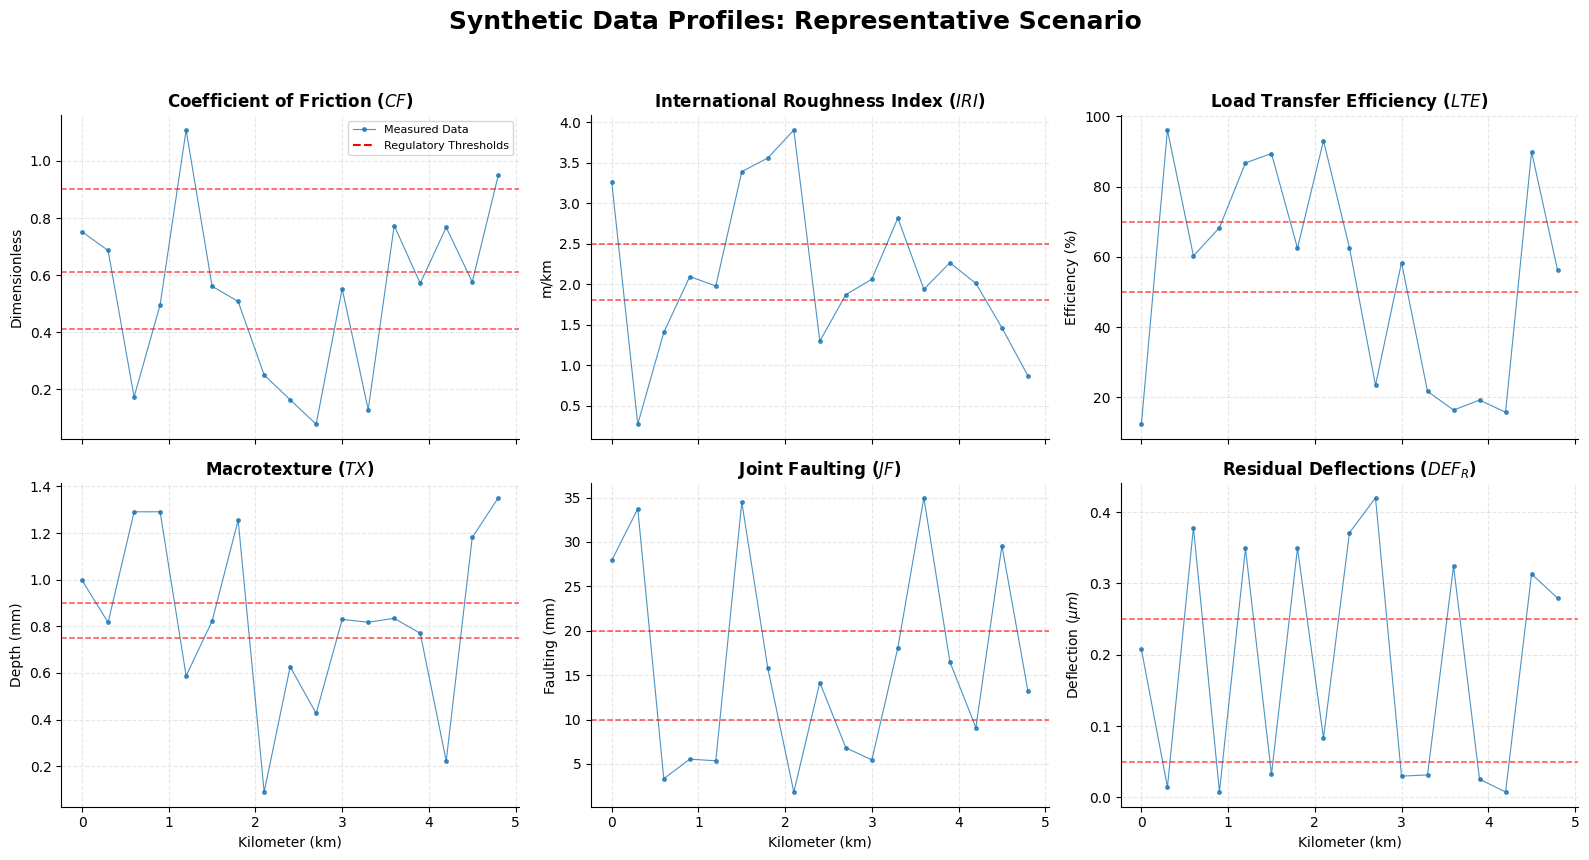

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import os

def graficar_paneles_por_columnas(df, umbrales_dict, nombre_escenario="Representative", carpeta_salida="graficas_resultados"):
    """
    Genera una imagen de 2x3 organizada por columnas temáticas:
    Col 1: Seguridad (CF, TX)
    Col 2: Servicialidad (IRI, JF)
    Col 3: Integridad (LTE, DEF)
    """
    if not os.path.exists(carpeta_salida):
        os.makedirs(carpeta_salida)

    # Definimos el orden exacto por COLUMNAS (Matplotlib llena por filas, así que reordenamos)
    # Fila 1: CF, IRI, LTE
    # Fila 2: TX, JF, DEF
    variables_ordenadas = ["CF", "IRI", "LTE", "TX", "JF", "DEF"]

    nrows, ncols = 2, 3
    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(16, 9), sharex=True)
    axes_flat = axes.flatten()

    fig.suptitle(f"Synthetic Data Profiles: {nombre_escenario} Scenario",
                 fontsize=18, fontweight='bold', y=0.98)

    nombres_titulos = {
        "CF": "Coefficient of Friction ($CF$)",
        "TX": "Macrotexture ($TX$)",
        "IRI": "International Roughness Index ($IRI$)",
        "JF": "Joint Faulting ($JF$)",
        "LTE": "Load Transfer Efficiency ($LTE$)",
        "DEF": "Residual Deflections ($DEF_R$)"
    }

    unidades_y = {
        "CF": "Dimensionless", "TX": "Depth (mm)",
        "IRI": "m/km", "JF": "Faulting (mm)",
        "LTE": "Efficiency (%)", "DEF": "Deflection ($\mu m$)"
    }

    for i, var in enumerate(variables_ordenadas):
        ax = axes_flat[i]

        # Graficar
        ax.plot(df["KM_Inicio"], df[var], marker="o", markersize=2.5,
                linewidth=0.8, color="#1f77b4", alpha=0.8, label="Measured Data")

        # Umbrales
        if var in umbrales_dict:
            limites = umbrales_dict[var]
            valores_y = sorted({v for l in limites.values() for v in l if v not in (0.0, float('inf'))})
            for y_val in valores_y:
                ax.axhline(y=y_val, linestyle="--", color="red", alpha=0.7, linewidth=1.1)
            if valores_y:
                ax.plot([], [], linestyle="--", color="red", label="Regulatory Thresholds")

        # Títulos y Etiquetas
        ax.set_title(nombres_titulos.get(var, var), fontsize=12, fontweight='bold')
        ax.set_ylabel(unidades_y.get(var, ""), fontsize=10)

        # Solo poner "Km" en la fila de abajo
        if i >= 3:
            ax.set_xlabel("Kilometer (km)", fontsize=10)

        ax.grid(True, linestyle='--', alpha=0.3)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

        # Leyenda solo en la primera para limpiar
        if i == 0:
            ax.legend(loc='upper right', fontsize=8)

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])

    nombre_archivo = f"Grid_Profiles_{nombre_escenario}_Columns.png"
    plt.savefig(os.path.join(carpeta_salida, nombre_archivo), dpi=300, bbox_inches="tight")
    plt.show()

# Ejecución
graficar_paneles_por_columnas(df_tramo_ida, umbrales, nombre_escenario="Representative")

#Methodology M1: Analytic Hierarchy Process (AHP)

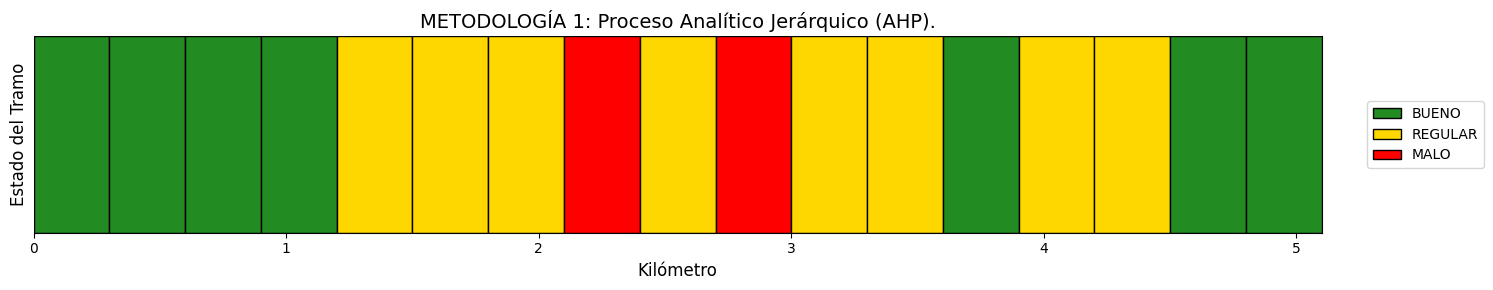

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches

# ==================== FUNCIÓN DE EVALUACIÓN DE TRAMO ====================

def evaluar_tramo(datos_tramo, pesos_globales, pesos_alternativas, umbrales):
    """
    datos_tramo        : dict con CF, TX, IRI, JF, LTE, DEF
    pesos_globales     : dict con pesos AHP por indicador
    pesos_alternativas : array [Bueno, Regular, Malo]
    umbrales           : dict de umbrales normativos
    """

    # ---  Alternativas de severidad ---
    mapa_alt = {
        "Bueno":   float(pesos_alternativas[0]),
        "Regular": float(pesos_alternativas[1]),
        "Malo":    float(pesos_alternativas[2])
    }

    clasificacion = {}

    # --- Clasificación por indicador ---
    for indicador, valor in datos_tramo.items():
        if indicador not in umbrales:
            continue

        if valor is None or (isinstance(valor, float) and np.isnan(valor)):
            continue

        # CF
        if indicador == 'CF':
            u = umbrales[indicador]
            if 'Malo_Alto' in u and valor >= u['Malo_Alto'][0]:
                clasificacion[indicador] = 'Malo'
            elif 'Malo_Bajo' in u and valor < u['Malo_Bajo'][1]:
                clasificacion[indicador] = 'Malo'
            elif u['Bueno'][0] <= valor < u['Bueno'][1]:
                clasificacion[indicador] = 'Bueno'
            elif u['Regular'][0] <= valor < u['Regular'][1]:
                clasificacion[indicador] = 'Regular'
            continue

        # TX
        if indicador == 'TX':
            u = umbrales[indicador]
            if valor < u['Malo'][1]:
                clasificacion[indicador] = 'Malo'
            elif u['Regular'][0] <= valor < u['Regular'][1]:
                clasificacion[indicador] = 'Regular'
            else:
                clasificacion[indicador] = 'Bueno'
            continue

        # Resto de indicadores
        for categoria, (lo, hi) in umbrales[indicador].items():
            if lo <= valor < hi:
                clasificacion[indicador] = (
                    "Malo" if categoria in ("Malo_Alto", "Malo_Bajo") else categoria
                )
                break

    # --- Cálculo AHP ---
    puntuacion = 0.0
    w_presentes = 0.0

    for ind, cat in clasificacion.items():
        if ind in pesos_globales:
            w = pesos_globales[ind]
            puntuacion += w * mapa_alt[cat]
            w_presentes += w

    max_teorico = w_presentes * mapa_alt["Bueno"] if w_presentes > 0 else 0.0

    # --- Severidad final ---
    if max_teorico == 0:
        severidad = "SIN_DATO"
    elif puntuacion >= 0.6 * max_teorico:
        severidad = "BUENO"
    elif puntuacion >= 0.3 * max_teorico:
        severidad = "REGULAR"
    else:
        severidad = "MALO"

    return puntuacion, severidad, clasificacion

# ==================== APLICAR EVALUACIÓN A CADA SEGMENTO ====================

resultados_evaluacion = []

for _, row in df_tramo_ida.iterrows():
    datos_indicadores = row[['IRI', 'JF', 'LTE', 'DEF', 'CF', 'TX']].to_dict()

    puntuacion, severidad, clasif = evaluar_tramo(
        datos_indicadores,
        pesos_globales,
        pesos_alternativas,  # Vector [Bueno, Regular, Malo]
        umbrales
    )

    resultados_evaluacion.append({
        'ID_Tramo': row['ID_Tramo'],
        'KM_Inicio': row['KM_Inicio'],
        'KM_Fin': row['KM_Fin'],
        'Puntuacion_AHP': puntuacion,
        'Severidad_AHP': severidad,
        # Opción para depurar:
        'Clasif': clasif
    })

df_resultados = pd.DataFrame(resultados_evaluacion)

# ==================== GRAFICACIÓN DE LAS ZONAS HOMOGÉNEAS ====================

colores_severidad = {
    "BUENO": '#228B22',
    "REGULAR": '#FFD700',
    "MALO": '#FF0000'
}

plt.figure(figsize=(15, 3))
ax = plt.gca()

section_length_km = longitud_segmento_metros / 1000  # Longitud de cada segmento en km

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(True)
ax.spines['bottom'].set_visible(True)
ax.spines['left'].set_visible(False)

rectangle_height = 1
line_thickness = 1.0

for index, row in df_resultados.iterrows():
    start_km = row['KM_Inicio']
    width = row['KM_Fin'] - row['KM_Inicio']
    zone_color = colores_severidad.get(row['Severidad_AHP'], 'black')

    rect = mpatches.Rectangle(
        (start_km, 0),
        width,
        rectangle_height,
        facecolor=zone_color,
        edgecolor='black',
        linewidth=line_thickness
    )
    ax.add_patch(rect)

ax.set_xlim(0, df_resultados['KM_Fin'].max())
ax.set_ylim(0, 1)
ax.set_yticks([])
ax.set_xlabel('Kilómetro', fontsize=12)
ax.set_ylabel('Estado del Tramo', fontsize=12)
plt.xticks(np.arange(0, longitud_total_km + 1, 1.0), fontsize=10)
ax.grid(False)

ax.set_title('METODOLOGÍA 1: Proceso Analítico Jerárquico (AHP).', fontsize=14)

handles = [
    mpatches.Patch(
        facecolor=colores_severidad[label],
        label=label,
        edgecolor='black',
        linewidth=line_thickness
    ) for label in ["BUENO", "REGULAR", "MALO"]
]

ax.legend(
    handles=handles,
    loc='center left',
    bbox_to_anchor=(1.03, 0.5),
    fontsize=10
)

plt.tight_layout()
#plt.savefig('MET-1.png',
            #bbox_inches='tight', pad_inches=0.1, transparent=True)
plt.show()


Resultados ida y vuelta

In [8]:
cols = ['IRI', 'JF', 'LTE', 'DEF', 'CF', 'TX']

# Verificación que Pesos alternativas sea vector
pesos_alt_vec = np.array(pesos_alternativas, dtype=float).ravel()

# ==================== EVALUACIÓN AHP: IDA ====================

resultados_ida = []

for _, row in df_tramo_ida.iterrows():
    datos_indicadores = {c: row.get(c, np.nan) for c in cols}

    puntuacion, severidad, _ = evaluar_tramo(
        datos_indicadores,
        pesos_globales,
        pesos_alt_vec,
        umbrales
    )

    resultados_ida.append({
        'Sentido': row.get('Sentido', 'IDA'),
        'ID_Tramo': row.get('ID_Tramo', np.nan),
        'KM_Inicio': row.get('KM_Inicio', np.nan),
        'KM_Fin': row.get('KM_Fin', np.nan),
        'Puntuacion_AHP': puntuacion,
        'Severidad_AHP': severidad
    })

df_resultados_ida = pd.DataFrame(resultados_ida)

# ==================== EVALUACIÓN AHP: VUELTA ====================

resultados_vuelta = []

for _, row in df_tramo_vuelta.iterrows():
    datos_indicadores = {c: row.get(c, np.nan) for c in cols}

    puntuacion, severidad, _ = evaluar_tramo(
        datos_indicadores,
        pesos_globales,
        pesos_alt_vec,
        umbrales
    )

    resultados_vuelta.append({
        'Sentido': row.get('Sentido', 'VUELTA'),
        'ID_Tramo': row.get('ID_Tramo', np.nan),
        'KM_Inicio': row.get('KM_Inicio', np.nan),
        'KM_Fin': row.get('KM_Fin', np.nan),
        'Puntuacion_AHP': puntuacion,
        'Severidad_AHP': severidad
    })

df_resultados_vuelta = pd.DataFrame(resultados_vuelta)


##Larguillo


###Carretera


LARGUILO DE ZONAS HOMOGÉNEAS (CARRETERA CON LOSAS)


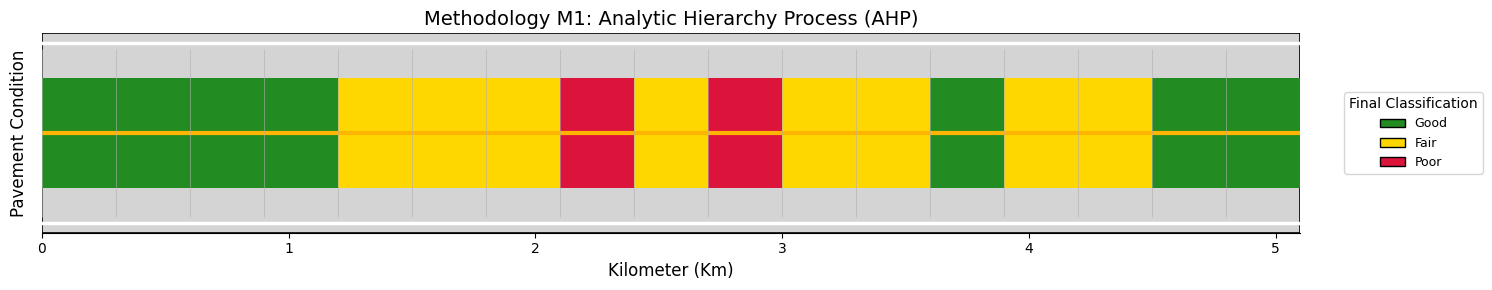

In [9]:
# ==================== GRÁFICA ESTILO CARRETERA CON LOSAS ====================

print("\n" + "="*60)
print("LARGUILO DE ZONAS HOMOGÉNEAS (CARRETERA CON LOSAS)")
print("="*60)

# Colores de severidad
colores_severidad = {
    "BUENO": '#228B22',     # verde
    "REGULAR": '#FFD700',   # amarillo dorado
    "MALO": '#DC143C'       # rojo
}

plt.figure(figsize=(15, 3))
ax = plt.gca()

section_length_km = longitud_segmento_metros / 1000   # 300 m -> 0.3 km
road_height = 1.0

# -------- 1. FONDO gris tipo concreto hidráulico --------
max_km = df_resultados['KM_Fin'].max()

carretera = mpatches.Rectangle(
    (0, 0),
    max_km,
    road_height,
    facecolor="#D4D4D4",   # gris claro – concreto hidráulico
    edgecolor='black',
    linewidth=1.2
)
ax.add_patch(carretera)

# -------- 2. LÍNEAS LATERALES --------
ax.plot([0, max_km], [0.95, 0.95], color='white', linewidth=2.5)
ax.plot([0, max_km], [0.05, 0.05], color='white', linewidth=2.5)

# -------- 3. LÍNEA CENTRAL DISCONTINUA --------
ax.plot([0, max_km], [0.50, 0.50], color='#FFB400', linewidth=3.0)

# -------- 4. DELIMITACIÓN DE LOSAS DE CONCRETO --------
longitud_losa_m = 300 #Representación visual únicamente
longitud_losa_km = longitud_losa_m / 1000.0   # 0.0045 km

x = 0.0
while x <= max_km + longitud_losa_km:
    # Línea vertical fina para marcar la junta
    ax.vlines(
        x,
        0.08,               # Arriba de la línea lateral inferior
        0.92,               # Aabajo de la línea lateral superior
        colors='#B0B0B0',   # Gris medio para que no domine
        linewidth=0.4,
        linestyles='-'
    )
    x += longitud_losa_km

# -------- 5. BANDA DE COLOR SEGÚN SEVERIDAD --------
band_height = 0.55
band_y = (road_height - band_height) / 2

for _, row in df_resultados.iterrows():
    start_km = row['KM_Inicio']
    zone_color = colores_severidad.get(str(row['Severidad_AHP']).strip(), (0, 0, 0, 0.4))

    rect = mpatches.Rectangle(
        (start_km, band_y),
        section_length_km,
        band_height,
        facecolor=zone_color,  # semitransparente
        edgecolor='none'
    )
    ax.add_patch(rect)

# -------- 6. CONFIGURACIÓN DE EJES --------
ax.set_xlim(0, max_km)
ax.set_ylim(0, road_height)
ax.set_yticks([])
plt.xticks(np.arange(0, longitud_total_km + 1, 1.0), fontsize=10)

ax.set_xlabel('Kilometer (Km)', fontsize=12)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(True)

ax.set_title("Methodology M1: Analytic Hierarchy Process (AHP)", fontsize=14)

# -------- 7. LEYENDA --------

# Colores de severidad
sev = {
    "Good": '#228B22',     # verde
    "Fair": '#FFD700',   # amarillo dorado
    "Poor": '#DC143C'       # rojo
}

handles = [
    mpatches.Patch(
        facecolor=c,
        label=label.strip(),
        edgecolor='black'
    ) for label, c in sev.items()
]

ax.legend(
    handles=handles,
    loc='center left',
    bbox_to_anchor=(1.03, 0.5),
    fontsize=9,
    title="Final Classification"
)

ax.set_ylabel("Pavement Condition", fontsize=12, labelpad=10)


plt.tight_layout()
plt.savefig("MET-1.png",
            dpi=300, bbox_inches="tight")

plt.show()

###Autopista

In [10]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

def graficar_autopista_dos_cuerpos(df_resultados_ida, df_resultados_vuelta,
                                   longitud_total_km):
    """
    df_resultados_ida / vuelta:
        columnas: KM_Inicio, KM_Fin, Severidad_AHP
    """

    # Colores de severidad
    colores_severidad = {
        "BUENO": '#228B22',        # verde
        "REGULAR": '#FFD700',   # amarillo dorado
        "MALO": '#DC143C'          # rojo
    }

    plt.figure(figsize=(15, 4))
    ax = plt.gca()

    # Parámetros geométricos
    body_height = 0.8        # Altura de cada cuerpo
    gap = 0.25               # Separación entre cuerpos (camellón)
    y_base_ida = 0.0         # Cuerpo inferior
    y_base_vuelta = body_height + gap  # Cuerpo superior
    max_km = float(max(df_resultados_ida["KM_Fin"].max(),
                   df_resultados_vuelta["KM_Fin"].max()))

    # ===== 1. Dibujar cuerpos gris concreto =====
    for y0 in [y_base_ida, y_base_vuelta]:
        carretera = mpatches.Rectangle(
            (0, y0),
            max_km,
            body_height,
            facecolor="#D4D4D4",  # gris concreto
            edgecolor='black',
            linewidth=1.2
        )
        ax.add_patch(carretera)

    # ===== 2. Líneas laterales (blanca derecha, amarilla izquierda) =====
    # Cuerpo inferior (IDA)
    # Derecha (orilla exterior) -> blanca
    ax.plot(
        [0, max_km],
        [y_base_ida + 0.05, y_base_ida + 0.05],
        color='white', linewidth=2.5
    )
    # Izquierda (camellón) -> amarilla
    ax.plot(
        [0, max_km],
        [y_base_ida + body_height - 0.05, y_base_ida + body_height - 0.05],
        color='#FFB400', linewidth=3
    )

    # ===== 3. Línea entre carriles =====
    for y0 in [y_base_ida, y_base_vuelta]:
        ax.plot([0, max_km], [y0 + body_height/2, y0 + body_height/2],
                color='white', linewidth=1.5, linestyle='--')

    # Cuerpo superior (VUELTA)
    # Izquierda (camellón) -> amarilla
    ax.plot(
        [0, max_km],
        [y_base_vuelta + 0.05, y_base_vuelta + 0.05],
        color='#FFB400', linewidth=3.0
    )
    # Derecha (orilla exterior) -> blanca
    ax.plot(
        [0, max_km],
        [y_base_vuelta + body_height - 0.05, y_base_vuelta + body_height - 0.05],
        color='white', linewidth=2.5
    )

    # ===== 5. Juntas de losas (opcional) =====
    longitud_losa_m = 80
    longitud_losa_km = longitud_losa_m / 1000.0
    x = 0.0
    while x <= max_km + longitud_losa_km:
        for y0 in [y_base_ida, y_base_vuelta]:
            ax.vlines(
                x,
                y0 + 0.07,
                y0 + body_height - 0.07,
                colors='#B0B0B0',
                linewidth=0.4
            )
        x += longitud_losa_km

    # ===== 6. Banda de severidad para cada cuerpo =====
    band_height = body_height * 0.6
    band_offset = (body_height - band_height) / 2

    # Cuerpo inferior (IDA)
    for _, row in df_resultados_ida.iterrows():
        start_km = row['KM_Inicio']
        width_km = row['KM_Fin'] - row['KM_Inicio']
        zone_color = colores_severidad.get(row['Severidad_AHP'], (0, 0, 0, 0.4))

        rect = mpatches.Rectangle(
            (start_km, y_base_ida + band_offset),
            width_km,
            band_height,
            facecolor=zone_color,
            edgecolor='none'
        )
        ax.add_patch(rect)

    # Cuerpo superior (VUELTA)
    for _, row in df_resultados_vuelta.iterrows():
        start_km = row['KM_Inicio']
        width_km = row['KM_Fin'] - row['KM_Inicio']
        zone_color = colores_severidad.get(row['Severidad_AHP'], (0, 0, 0, 0.4))

        rect = mpatches.Rectangle(
            (start_km, y_base_vuelta + band_offset),
            width_km,
            band_height,
            facecolor=zone_color,
            edgecolor='none'
        )
        ax.add_patch(rect)

    # ===== 7. Configuración de ejes =====
    ax.set_xlim(0, max_km)
    ax.set_ylim(-0.1, y_base_vuelta + body_height + 0.1)
    ax.set_yticks([])
    ax.set_xlabel('Kilómetro', fontsize=12)
    plt.xticks(np.arange(0, longitud_total_km + 1, 1.0), fontsize=10)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.spines['bottom'].set_visible(True)

    ax.set_title("Methodology M1: Analytic Hierarchy Process (AHP)", fontsize=14)

    # -------- 7. LEYENDA --------
    handles = [
        mpatches.Patch(
            facecolor=c,
            label=label.strip(),
            edgecolor='black'
        ) for label, c in colores_severidad.items()
    ]

    ax.legend(
    handles=handles,
    loc='center left',
    bbox_to_anchor=(1.03, 0.5),
    title="Final Classification",
    title_fontsize=10,
    fontsize=9
)


    ax.set_ylabel("Estado del tramo", fontsize=12, labelpad=10)

    plt.tight_layout()
    #plt.savefig("MET-1-AUTOPISTA.png", dpi=300, bbox_inches="tight")
    plt.show()



Cadenamiento a decimal

In [11]:
#=======================AUTOPISTA=================================
import pandas as pd
import numpy as np

def km_estacado_a_km(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip()
    if "+" in s:
        a, b = s.split("+", 1)
        return float(a) + float(b)/1000.0
    return float(s)

for dfx in [df_resultados_ida, df_resultados_vuelta]:
    dfx["KM_Inicio"] = dfx["KM_Inicio"].apply(km_estacado_a_km)
    dfx["KM_Fin"]    = dfx["KM_Fin"].apply(km_estacado_a_km)

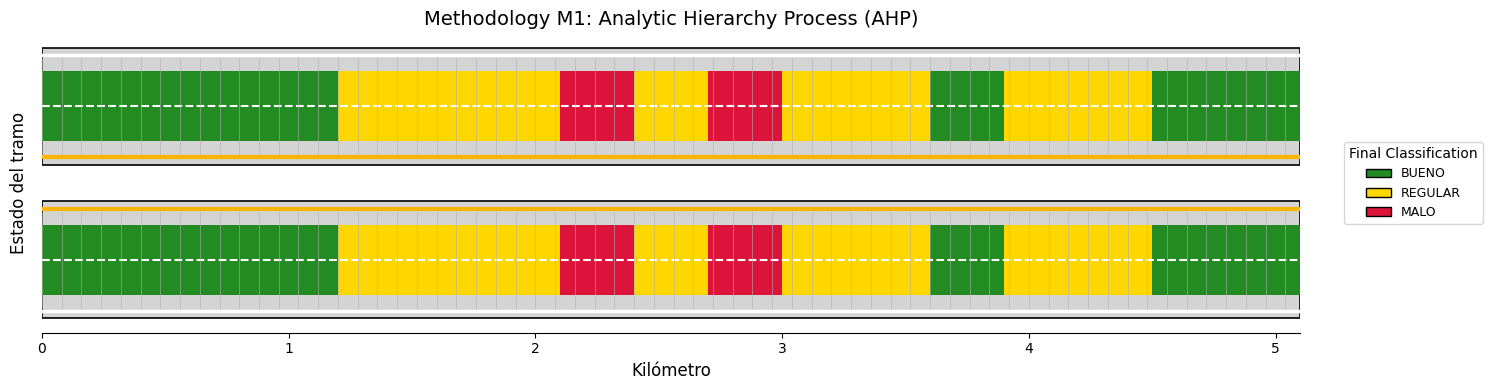

In [12]:
graficar_autopista_dos_cuerpos(df_resultados_ida, df_resultados_vuelta, longitud_total_km)

###Tramos

In [13]:
def contar_tramos_por_severidad_met1(df):
    s = (df['Severidad_AHP']
         .fillna('SIN_CLASIFICAR')
         .astype(str)
         .str.strip())

    return s.value_counts()

print(contar_tramos_por_severidad_met1(df_resultados))

Severidad_AHP
REGULAR    8
BUENO      7
MALO       2
Name: count, dtype: int64


#Methodology M2: Cascade AHP (Strict)

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib import colors as mcolors

# ==================== PESOS AHP (alternativas) ====================

pesos_alternativas = {
    "BUENO":   0.6000,
    "REGULAR": 0.3000,
    "MALO":    0.1000
}

# Pesos relativos por nivel (suman 1 en cada nivel)
pesos_nivel = {
    'Seguridad':    {'CF': 0.5,     'TX': 0.5},
    'Operatividad': {'IRI': 0.8333, 'JF': 0.1667},
    'Integridad':   {'LTE': 0.5,    'DEF': 0.5}
}

MAX_NIVEL = pesos_alternativas['BUENO']  # 0.6

def _to_float_or_nan(x):
    try:
        return float(x)
    except Exception:
        return np.nan

def clasificar_indicador(indicador, valor):
    """Devuelve BUENO / REGULAR / MALO según umbrales. Si no se puede clasificar, MALO."""
    if indicador not in umbrales or valor is None:
        return 'MALO'

    v = _to_float_or_nan(valor)
    if np.isnan(v):
        return 'MALO'

    if indicador == 'CF':
        u = umbrales['CF']
        if v >= u['Malo_Alto'][0]:
            return 'MALO'
        if u['Bueno'][0] <= v < u['Bueno'][1]:
            return 'BUENO'
        if u['Regular'][0] <= v < u['Regular'][1]:
            return 'REGULAR'
        if u['Malo_Bajo'][0] <= v < u['Malo_Bajo'][1]:
            return 'MALO'
        return 'MALO'

    if indicador == 'TX':
        u = umbrales['TX']
        if u['Malo'][0] <= v < u['Malo'][1]:
            return 'MALO'
        if v >= u['Bueno'][0]:
            return 'BUENO'
        if u['Regular'][0] <= v < u['Regular'][1]:
            return 'REGULAR'
        return 'MALO'

    # IRI, JF, LTE, DEF
    for categoria_key, (lo, hi) in umbrales[indicador].items():
        if lo <= v < hi:
            return categoria_key.upper()

    return 'MALO'

def _clasificar_puntaje_nivel(p):
    """Clasifica BUENO/REGULAR/MALO usando tu regla relativa."""
    umbral_bueno   = 0.6 * MAX_NIVEL   # 0.36
    umbral_regular = 0.3 * MAX_NIVEL   # 0.18
    if p >= umbral_bueno:
        return 'BUENO'
    elif p >= umbral_regular:
        return 'REGULAR'
    return 'MALO'

def evaluar_nivel_seguridad(row):
    cf_clas = clasificar_indicador('CF', row.get('CF', np.nan))
    tx_clas = clasificar_indicador('TX', row.get('TX', np.nan))
    p = (pesos_nivel['Seguridad']['CF'] * pesos_alternativas[cf_clas] +
         pesos_nivel['Seguridad']['TX'] * pesos_alternativas[tx_clas])
    sev = _clasificar_puntaje_nivel(p)
    return p, sev, cf_clas, tx_clas

def evaluar_nivel_operatividad(row):
    iri_clas = clasificar_indicador('IRI', row.get('IRI', np.nan))
    jf_clas  = clasificar_indicador('JF',  row.get('JF',  np.nan))
    p = (pesos_nivel['Operatividad']['IRI'] * pesos_alternativas[iri_clas] +
         pesos_nivel['Operatividad']['JF']  * pesos_alternativas[jf_clas])
    sev = _clasificar_puntaje_nivel(p)
    return p, sev, iri_clas, jf_clas

def evaluar_nivel_integridad(row):
    lte_clas = clasificar_indicador('LTE', row.get('LTE', np.nan))
    def_clas = clasificar_indicador('DEF', row.get('DEF', np.nan))
    p = (pesos_nivel['Integridad']['LTE'] * pesos_alternativas[lte_clas] +
         pesos_nivel['Integridad']['DEF'] * pesos_alternativas[def_clas])
    sev = _clasificar_puntaje_nivel(p)
    return p, sev, lte_clas, def_clas


In [15]:
def aplicar_metodologia2(df_tramo):
    """
    METODOLOGÍA 2: Segmentación jerárquica (cascada).
    - NIVEL 1: Seguridad (CF, TX) -> solo BUENO avanza.
    - NIVEL 2: Operatividad (IRI, JF) -> solo BUENO avanza.
    - NIVEL 3: Integridad (LTE, DEF).
    REGULAR y MALO se detienen en el nivel donde “no cumplan”.

    Índice_Condicion = p / MAX_NIVEL (normalizado en escala del nivel).
    """

    resultados = []

    for _, row in df_tramo.iterrows():
        # --- usar get() para no tronar si falta algo ---
        seg = {
            'Sentido': row.get('Sentido', ''),
            'ID_Tramo': row.get('ID_Tramo', np.nan),
            'KM_Inicio': row.get('KM_Inicio', np.nan),
            'KM_Fin': row.get('KM_Fin', np.nan),

            'CF_Valor': row.get('CF', np.nan),
            'TX_Valor': row.get('TX', np.nan),
            'IRI_Valor': row.get('IRI', np.nan),
            'JF_Valor': row.get('JF', np.nan),
            'LTE_Valor': row.get('LTE', np.nan),
            'DEF_Valor': row.get('DEF', np.nan),

            'CF_Clasif': None,
            'TX_Clasif': None,
            'IRI_Clasif': None,
            'JF_Clasif': None,
            'LTE_Clasif': None,
            'DEF_Clasif': None,

            'Clasif_Nivel1_Seguridad': None,
            'Clasif_Nivel2_Operatividad': None,
            'Clasif_Nivel3_Integridad': None,

            'Puntuacion_Nivel1': 0.0,
            'Puntuacion_Nivel2': 0.0,
            'Puntuacion_Nivel3': 0.0,

            'Indice_Condicion': 0.0,
            'Clasif_Final_Homogenea': None
        }

        # ========= NIVEL 1: SEGURIDAD =========
        p1, sev1, cf_c, tx_c = evaluar_nivel_seguridad(row)
        sev1 = str(sev1).strip()
        cf_c = str(cf_c).strip()
        tx_c = str(tx_c).strip()

        seg['Puntuacion_Nivel1'] = float(p1)
        seg['Clasif_Nivel1_Seguridad'] = sev1
        seg['CF_Clasif'] = cf_c
        seg['TX_Clasif'] = tx_c

        if sev1 != 'BUENO':
            seg['Clasif_Final_Homogenea'] = 'Seguridad Regular' if sev1 == 'REGULAR' else 'Seguridad Malo'
            seg['Indice_Condicion'] = (float(p1) / MAX_NIVEL) if MAX_NIVEL > 0 else 0.0
            resultados.append(seg)
            continue

        # ========= NIVEL 2: OPERATIVIDAD =========
        p2, sev2, iri_c, jf_c = evaluar_nivel_operatividad(row)
        sev2 = str(sev2).strip()
        iri_c = str(iri_c).strip()
        jf_c = str(jf_c).strip()

        seg['Puntuacion_Nivel2'] = float(p2)
        seg['Clasif_Nivel2_Operatividad'] = sev2
        seg['IRI_Clasif'] = iri_c
        seg['JF_Clasif'] = jf_c

        if sev2 != 'BUENO':
            seg['Clasif_Final_Homogenea'] = 'Operatividad Regular' if sev2 == 'REGULAR' else 'Operatividad Malo'
            seg['Indice_Condicion'] = (float(p2) / MAX_NIVEL) if MAX_NIVEL > 0 else 0.0
            resultados.append(seg)
            continue

        # ========= NIVEL 3: INTEGRIDAD =========
        p3, sev3, lte_c, def_c = evaluar_nivel_integridad(row)
        sev3 = str(sev3).strip()
        lte_c = str(lte_c).strip()
        def_c = str(def_c).strip()

        seg['Puntuacion_Nivel3'] = float(p3)
        seg['Clasif_Nivel3_Integridad'] = sev3
        seg['LTE_Clasif'] = lte_c
        seg['DEF_Clasif'] = def_c

        seg['Indice_Condicion'] = (float(p3) / MAX_NIVEL) if MAX_NIVEL > 0 else 0.0

        if sev3 == 'BUENO':
            seg['Clasif_Final_Homogenea'] = 'Integridad Estructural Buena'
        elif sev3 == 'REGULAR':
            seg['Clasif_Final_Homogenea'] = 'Integridad Estructural Regular'
        else:
            seg['Clasif_Final_Homogenea'] = 'Integridad Estructural Malo'

        resultados.append(seg)

    df_res = pd.DataFrame(resultados)

    df_res['Clasif_Final_Homogenea'] = df_res['Clasif_Final_Homogenea'].fillna('Seguridad Malo')

    return df_res


In [16]:
df_resultados_ida_m2 = aplicar_metodologia2(df_tramo_ida)
df_resultados_vuelta_m2 = aplicar_metodologia2(df_tramo_vuelta)

##Larguillo


###Autopista

In [17]:
colores_met2 = {
    "Seguridad Malo":                 '#DC143C',  # Crimson
    "Seguridad Regular":              '#FF8C00',  # DarkOrange
    "Operatividad Malo":              '#FFA500',  # Orange
    "Operatividad Regular":           '#FFD700',  # Gold
    "Integridad Estructural Malo":    '#8B0000',  # Dark Red
    "Integridad Estructural Regular": '#B22222',  # Firebrick
    "Integridad Estructural Buena":   '#228B22',  # Verde
}


In [18]:
def graficar_autopista_dos_cuerpos_met2(df_resultados_ida_m2,
                                        df_resultados_vuelta_m2,
                                        longitud_total_km):
    max_km = float(max(df_resultados_ida["KM_Fin"].max(),
    df_resultados_vuelta["KM_Fin"].max()))
    body_height = 0.8
    gap = 0.25

    y_base_ida = 0.0
    y_base_vuelta = body_height + gap

    plt.figure(figsize=(15, 4))
    ax = plt.gca()

    # 1. Cuerpos gris
    for y0 in [y_base_ida, y_base_vuelta]:
        carretera = mpatches.Rectangle(
            (0, y0),
            max_km,
            body_height,
            facecolor="#D4D4D4",
            edgecolor='black',
            linewidth=1.2
        )
        ax.add_patch(carretera)

    # 2. Líneas laterales
    amarillo = "#FFB400"

    # IDA
    ax.plot([0, max_km],
            [y_base_ida + 0.05, y_base_ida + 0.05],
            color='white', linewidth=2.5)
    ax.plot([0, max_km],
            [y_base_ida + body_height - 0.05,
             y_base_ida + body_height - 0.05],
            color=amarillo, linewidth=3.0)

    # VUELTA
    ax.plot([0, max_km],
            [y_base_vuelta + 0.05, y_base_vuelta + 0.05],
            color=amarillo, linewidth=3.0)
    ax.plot([0, max_km],
            [y_base_vuelta + body_height - 0.05,
             y_base_vuelta + body_height - 0.05],
            color='white', linewidth=2.5)

    # 3. Línea entre carriles
    for y0 in [y_base_ida, y_base_vuelta]:
        ax.plot([0, max_km],
                [y0 + body_height/2, y0 + body_height/2],
                color='white', linewidth=1.5, linestyle='--')

    # 4. Juntas de losas
    longitud_losa_m = 300
    longitud_losa_km = longitud_losa_m / 1000.0
    x = 0.0
    while x <= max_km + longitud_losa_km:
        for y0 in [y_base_ida, y_base_vuelta]:
            ax.vlines(x,
                      y0 + 0.07,
                      y0 + body_height - 0.07,
                      colors='#B0B0B0',
                      linewidth=0.4)
        x += longitud_losa_km

    # 5. Bandas de severidad
    band_height = body_height * 0.6
    band_offset = (body_height - band_height) / 2

    # IDA
    for _, row in df_resultados_ida_m2.iterrows():
        start_km = row['KM_Inicio']
        width_km = row['KM_Fin'] - row['KM_Inicio']

        clasif = str(row['Clasif_Final_Homogenea']).strip()  # <- FIX
        color_base = colores_met2.get(clasif, '#AAAAAA')
        r, g, b = mcolors.to_rgb(color_base)

        rect = mpatches.Rectangle(
            (start_km, y_base_ida + band_offset),
            width_km,
            band_height,
            facecolor=(r, g, b, 1.0),
            edgecolor='none'
        )
        ax.add_patch(rect)

    # VUELTA
    for _, row in df_resultados_vuelta_m2.iterrows():
        start_km = row['KM_Inicio']
        width_km = row['KM_Fin'] - row['KM_Inicio']

        clasif = str(row['Clasif_Final_Homogenea']).strip()  # <- FIX
        color_base = colores_met2.get(clasif, '#AAAAAA')
        r, g, b = mcolors.to_rgb(color_base)

        rect = mpatches.Rectangle(
            (start_km, y_base_vuelta + band_offset),
            width_km,
            band_height,
            facecolor=(r, g, b, 1.0),
            edgecolor='none'
        )
        ax.add_patch(rect)

    # 6. Ejes
    ax.set_xlim(0, max_km)
    ax.set_ylim(-0.1, y_base_vuelta + body_height + 0.1)
    ax.set_yticks([])
    ax.set_xlabel('Kilómetro', fontsize=12)
    ax.set_ylabel('Estado del tramo', fontsize=12)
    plt.xticks(np.arange(0, longitud_total_km + 1, 1.0), fontsize=10)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.spines['bottom'].set_visible(True)

    ax.set_title('Methodology M2: Cascade AHP (Strict)',
                 fontsize=14)

    # 7. Leyenda
    handles = [
        mpatches.Patch(facecolor=colores_met2[label],
                       edgecolor='black',
                       label=label)
        for label in colores_met2.keys()
    ]
    ax.legend(handles=handles,
              loc='center left',
              bbox_to_anchor=(1.02, 0.5),
              fontsize=9,
              title="Final Classification")

    plt.tight_layout()
    #plt.savefig('metodologia2_autopista_dos_cuerpos.png',
                #dpi=300,
                #bbox_inches='tight')
    plt.show()


Cadenamiento a decimal

In [19]:
def km_estacado_a_km(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip()
    if "+" in s:
        a, b = s.split("+", 1)
        return float(a) + float(b)/1000.0
    return float(s)

for dfx in [df_resultados_ida_m2, df_resultados_vuelta_m2]:
    dfx["KM_Inicio"] = dfx["KM_Inicio"].apply(km_estacado_a_km)
    dfx["KM_Fin"]    = dfx["KM_Fin"].apply(km_estacado_a_km)


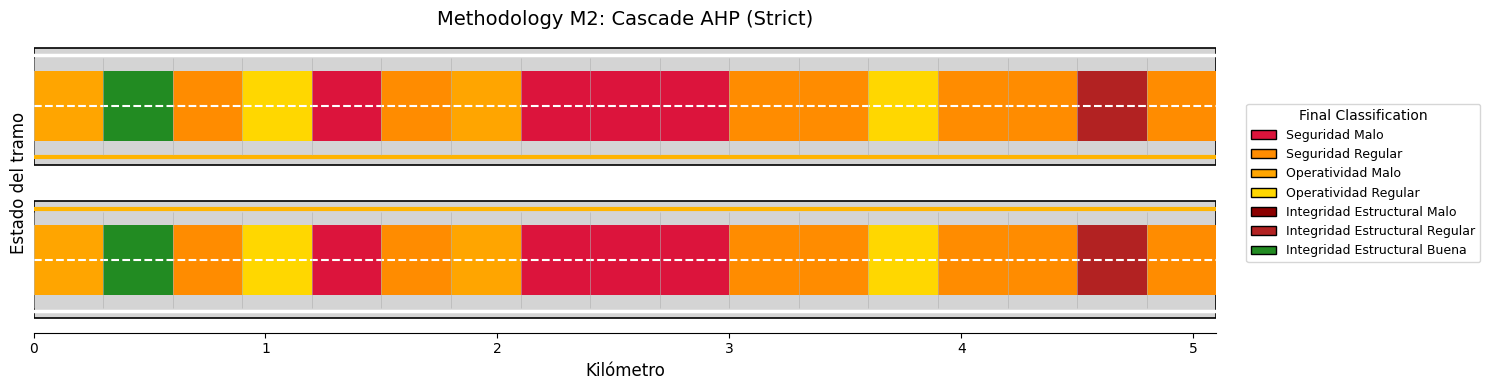

In [20]:
graficar_autopista_dos_cuerpos_met2(
    df_resultados_ida_m2,
    df_resultados_vuelta_m2,
    longitud_total_km
)



###Carretera

In [21]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib import colors as mcolors

# ==================== METODOLOGÍA 2: 1 SOLO SENTIDO (CARRETERA CON LOZAS) ====================

def graficar_metodologia2_un_sentido(df_resultados_m2,
                                    longitud_total_km,
                                    colores_met2,
                                    longitud_losa_m=300,
                                    alpha_banda=0.45,
                                    nombre_archivo="met-2.png",
                                    titulo="Methodology M2: Cascade AHP (Strict)"):
    """
    df_resultados_m2: DataFrame con columnas KM_Inicio, KM_Fin, Clasif_Final_Homogenea
    colores_met2: dict { "Seguridad Malo": "#...", ... }
    """

    df_plot = df_resultados_m2.copy()
    df_plot['Clasif_Final_Homogenea'] = df_plot['Clasif_Final_Homogenea'].astype(str).str.strip()

    plt.figure(figsize=(15, 3))
    ax = plt.gca()

    road_height = 1.0
    max_km = float(df_plot["KM_Fin"].max())

    # -------- 1. FONDO gris tipo concreto hidráulico --------
    carretera = mpatches.Rectangle(
        (0, 0),
        max_km,
        road_height,
        facecolor="#D4D4D4",
        edgecolor='black',
        linewidth=1.2
    )
    ax.add_patch(carretera)

    # -------- 2. LÍNEAS LATERALES --------
    ax.plot([0, max_km], [0.95, 0.95], color='white', linewidth=2.5)
    ax.plot([0, max_km], [0.05, 0.05], color='white', linewidth=2.5)

    # -------- 3. LÍNEA CENTRAL --------
    ax.plot([0, max_km], [0.50, 0.50], color='#FFB400', linewidth=3.0)

    # -------- 4. JUNTAS DE LOSAS --------
    longitud_losa_km = longitud_losa_m / 1000.0
    x = 0.0
    while x <= max_km + longitud_losa_km:
        ax.vlines(
            x,
            0.08,
            0.92,
            colors='#B0B0B0',
            linewidth=0.4,
            linestyles='-'
        )
        x += longitud_losa_km

    # -------- 5. BANDA DE COLOR SEGÚN CLASIFICACIÓN FINAL --------
    band_height = 0.55
    band_y = (road_height - band_height) / 2

    for _, row in df_plot.iterrows():
        start_km = km_estacado_a_km(row['KM_Inicio'])
        end_km   = km_estacado_a_km(row['KM_Fin'])
        if np.isnan(start_km) or np.isnan(end_km):
            continue
        width_km = max(end_km - start_km, 0)

        clasif = row['Clasif_Final_Homogenea']
        color_hex = colores_met2.get(clasif, '#AAAAAA')  # gris si no coincide
        r, g, b = mcolors.to_rgb(color_hex)

        rect = mpatches.Rectangle(
            (start_km, band_y),
            width_km,                 # usa el ancho real del tramo
            band_height,
            facecolor=(r, g, b, 1.0),
            edgecolor='none'
        )
        ax.add_patch(rect)

    # -------- 6. CONFIGURACIÓN DE EJES --------
    ax.set_xlim(0, max_km)
    ax.set_ylim(0, road_height)
    ax.set_yticks([])
    ax.set_xlabel('Kilometer (Km)', fontsize=12)
    plt.xticks(np.arange(0, max_km, 1.0), fontsize=10)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.spines['bottom'].set_visible(True)

    ax.set_title(titulo, fontsize=14)

    # -------- 7. LEYENDA --------

    colors_met2 = {
    "Poor Safety":                 '#DC143C',  # Crimson
    "Fair Safety":              '#FF8C00',  # DarkOrange
    "Poor Serviceability":              '#FFA500',  # Orange
    "Fair Serviceability":           '#FFD700',  # Gold
    "Poor Structural Integrity":    '#8B0000',  # Dark Red
    "Fair Structural Integrity": '#B22222',  # Firebrick
    "Good Structural Integrity":   '#228B22',  # Verde
    }
    handles = [
        mpatches.Patch(
            facecolor=colors_met2[label],
            edgecolor='black',
            label=label
        )
        for label in colors_met2.keys()
    ]
    ax.legend(handles=handles, loc='center left', bbox_to_anchor=(1.03, 0.5), fontsize=9, title="Final Classification")

    ax.set_ylabel("Pvavement Condition", fontsize=12, labelpad=10)

    plt.tight_layout()
    plt.savefig("MET-2", dpi=300, bbox_inches="tight")
    plt.show()


Ida

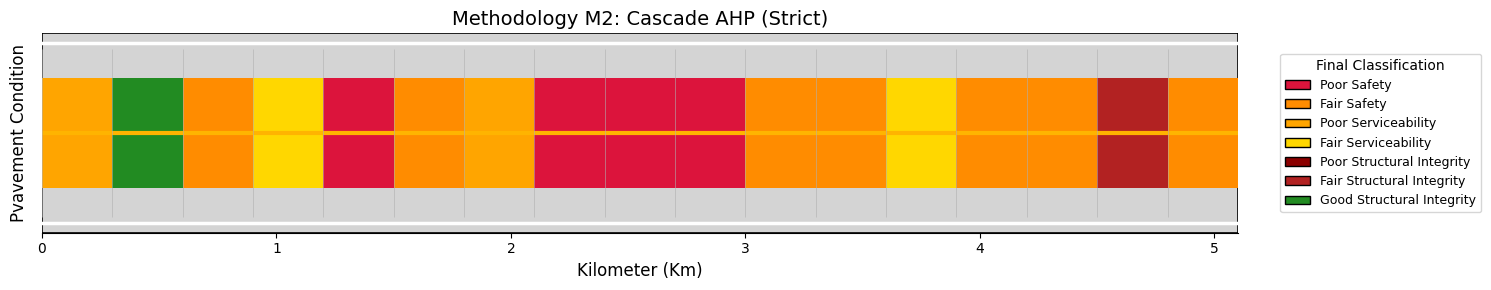

In [22]:
graficar_metodologia2_un_sentido(
    df_resultados_m2=df_resultados_ida_m2,
    longitud_total_km=longitud_total_km,
    colores_met2=colores_met2,
    nombre_archivo="MET-2.png",
    titulo="Methodology M2: Cascade AHP (Strict)"
)


Vuelta

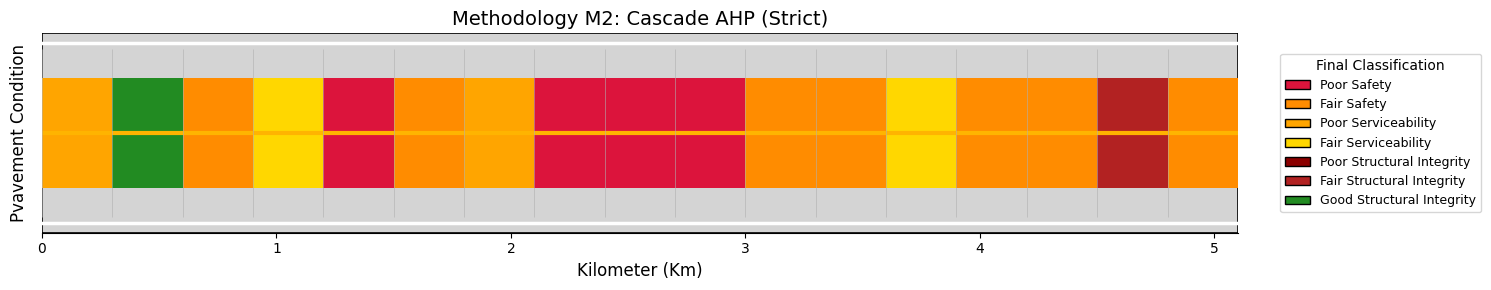

In [23]:
graficar_metodologia2_un_sentido(
    df_resultados_m2=df_resultados_vuelta_m2,
    longitud_total_km=longitud_total_km,
    colores_met2=colores_met2,
    nombre_archivo="metodologia2_vuelta_un_sentido.png",
    titulo="Methodology M2: Cascade AHP (Strict)"
)


###Tramos

In [24]:
def contar_tramos_por_severidad(df):
    # Normaliza texto por si hay espacios / NaN / mayúsculas
    s = (df['Clasif_Final_Homogenea']
         .fillna('SIN_CLASIFICAR')
         .astype(str)
         .str.strip())

    return s.value_counts()

print(contar_tramos_por_severidad(df_resultados_ida_m2))
print(contar_tramos_por_severidad(df_resultados_vuelta_m2))

Clasif_Final_Homogenea
Seguridad Regular                 7
Seguridad Malo                    4
Operatividad Regular              2
Operatividad Malo                 2
Integridad Estructural Buena      1
Integridad Estructural Regular    1
Name: count, dtype: int64
Clasif_Final_Homogenea
Seguridad Regular                 7
Seguridad Malo                    4
Operatividad Regular              2
Operatividad Malo                 2
Integridad Estructural Buena      1
Integridad Estructural Regular    1
Name: count, dtype: int64


#Methodology M3: Cascade AHP (Tolerant)


In [25]:
import numpy as np
import pandas as pd

def aplicar_metodologia3(df_tramo):
    """
    METODOLOGÍA 3: Segmentación jerárquica amplia (AHP).
    - NIVEL 1: Seguridad (CF, TX) -> BUENO y REGULAR avanzan; solo MALO se delimita aquí.
    - NIVEL 2: Operatividad (IRI, JF) -> BUENO y REGULAR avanzan; solo MALO se delimita aquí.
    - NIVEL 3: Integridad (LTE, DEF) -> clasificación final (BUENO / REGULAR / MALO).

    La clasificación final indica dónde se "detuvo" por MALO, o el resultado en Integridad si llegó.
    Indice_Condicion = p / MAX_NIVEL del último nivel evaluado.
    """

    resultados = []

    for _, row in df_tramo.iterrows():

        seg = {
            'Sentido': row.get('Sentido', ''),
            'ID_Tramo': row.get('ID_Tramo', np.nan),
            'KM_Inicio': row.get('KM_Inicio', np.nan),
            'KM_Fin': row.get('KM_Fin', np.nan),

            'CF_Valor': row.get('CF', np.nan),
            'TX_Valor': row.get('TX', np.nan),
            'IRI_Valor': row.get('IRI', np.nan),
            'JF_Valor': row.get('JF', np.nan),
            'LTE_Valor': row.get('LTE', np.nan),
            'DEF_Valor': row.get('DEF', np.nan),

            'CF_Clasif': None,
            'TX_Clasif': None,
            'IRI_Clasif': None,
            'JF_Clasif': None,
            'LTE_Clasif': None,
            'DEF_Clasif': None,

            'Clasif_Nivel1_Seguridad': None,
            'Clasif_Nivel2_Operatividad': None,
            'Clasif_Nivel3_Integridad': None,

            'Puntuacion_Nivel1': 0.0,
            'Puntuacion_Nivel2': 0.0,
            'Puntuacion_Nivel3': 0.0,

            'Indice_Condicion': 0.0,
            'Clasif_Final_Homogenea': None
        }

        # ========= NIVEL 1: SEGURIDAD =========
        p1, sev1, cf_c, tx_c = evaluar_nivel_seguridad(row)
        sev1 = str(sev1).strip()
        seg['Puntuacion_Nivel1'] = float(p1)
        seg['Clasif_Nivel1_Seguridad'] = sev1
        seg['CF_Clasif'] = str(cf_c).strip()
        seg['TX_Clasif'] = str(tx_c).strip()

        # Met 3: SOLO se detiene si es MALO
        if sev1 == 'MALO':
            seg['Clasif_Final_Homogenea'] = 'Seguridad Malo'
            seg['Indice_Condicion'] = (float(p1) / MAX_NIVEL) if MAX_NIVEL > 0 else 0.0
            resultados.append(seg)
            continue

        # ========= NIVEL 2: OPERATIVIDAD =========
        p2, sev2, iri_c, jf_c = evaluar_nivel_operatividad(row)
        sev2 = str(sev2).strip()
        seg['Puntuacion_Nivel2'] = float(p2)
        seg['Clasif_Nivel2_Operatividad'] = sev2
        seg['IRI_Clasif'] = str(iri_c).strip()
        seg['JF_Clasif'] = str(jf_c).strip()

        # Met 3: SOLO se detiene si es MALO
        if sev2 == 'MALO':
            seg['Clasif_Final_Homogenea'] = 'Operatividad Malo'
            seg['Indice_Condicion'] = (float(p2) / MAX_NIVEL) if MAX_NIVEL > 0 else 0.0
            resultados.append(seg)
            continue

        # ========= NIVEL 3: INTEGRIDAD =========
        p3, sev3, lte_c, def_c = evaluar_nivel_integridad(row)
        sev3 = str(sev3).strip()
        seg['Puntuacion_Nivel3'] = float(p3)
        seg['Clasif_Nivel3_Integridad'] = sev3
        seg['LTE_Clasif'] = str(lte_c).strip()
        seg['DEF_Clasif'] = str(def_c).strip()
        seg['Indice_Condicion'] = (float(p3) / MAX_NIVEL) if MAX_NIVEL > 0 else 0.0

        # Aquí sí se permite BUENO/REGULAR/MALO como resultado final
        if sev3 == 'BUENO':
            seg['Clasif_Final_Homogenea'] = 'Integridad Estructural Buena'
        elif sev3 == 'REGULAR':
            seg['Clasif_Final_Homogenea'] = 'Integridad Estructural Regular'
        else:
            seg['Clasif_Final_Homogenea'] = 'Integridad Estructural Malo'

        resultados.append(seg)

    df_res = pd.DataFrame(resultados)

    df_res['Clasif_Final_Homogenea'] = df_res['Clasif_Final_Homogenea'].fillna('Seguridad Malo')

    return df_res


In [26]:
colores_met3 = {
    "Seguridad Malo":                 "#DC143C",  # Crimson
    "Operatividad Malo":              "#FFA500",  # Orange
    "Integridad Estructural Malo":    "#8B0000",  # Dark Red
    "Integridad Estructural Regular": "#B22222",  # Firebrick
    "Integridad Estructural Buena":   "#228B22"   # Verde
}


##Larguillo


###Carretera

In [27]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib import colors as mcolors

def graficar_metodologia3_un_sentido(df_resultados_m3,
                                    longitud_total_km,
                                    colores_met3,
                                    longitud_losa_m=300,
                                    alpha_banda=0.45,
                                    nombre_archivo="MET-3.png",
                                    titulo="Methodology M3: Cascade AHP (Tolerant)"):
    """
    Dibuja 1 sentido estilo 'carretera con losas' usando Clasif_Final_Homogenea (Met 3).
    Requiere columnas: KM_Inicio, KM_Fin, Clasif_Final_Homogenea
    """

    df_plot = df_resultados_m3.copy()
    df_plot['Clasif_Final_Homogenea'] = df_plot['Clasif_Final_Homogenea'].astype(str).str.strip()

    plt.figure(figsize=(15, 3))
    ax = plt.gca()

    road_height = 1.0

    df_plot["KM_Inicio"] = df_plot["KM_Inicio"].apply(km_estacado_a_km)
    df_plot["KM_Fin"]    = df_plot["KM_Fin"].apply(km_estacado_a_km)
    max_km = float(df_plot["KM_Fin"].max())

    # 1) Fondo gris
    carretera = mpatches.Rectangle(
        (0, 0), max_km, road_height,
        facecolor="#D4D4D4", edgecolor="black", linewidth=1.2
    )
    ax.add_patch(carretera)

    # 2) Líneas laterales
    ax.plot([0, max_km], [0.95, 0.95], color='white', linewidth=2.5)
    ax.plot([0, max_km], [0.05, 0.05], color='white', linewidth=2.5)

    # 3) Línea central
    ax.plot([0, max_km], [0.50, 0.50], color="#FFB400", linewidth=3.0)

    # 4) Juntas de losas
    losa_km = longitud_losa_m / 1000.0
    x = 0.0
    while x <= max_km + losa_km:
        ax.vlines(x, 0.08, 0.92, colors="#B0B0B0", linewidth=0.4)
        x += losa_km

    # 5) Banda de color
    band_height = 0.55
    band_y = (road_height - band_height) / 2

    for _, row in df_plot.iterrows():
        start_km = km_estacado_a_km(row['KM_Inicio'])
        end_km   = km_estacado_a_km(row['KM_Fin'])
        if np.isnan(start_km) or np.isnan(end_km):
            continue
        width_km = max(end_km - start_km, 0.0)

        clasif = str(row['Clasif_Final_Homogenea']).strip()
        color_hex = colores_met3.get(clasif, "#AAAAAA")
        r, g, b = mcolors.to_rgb(color_hex)

        rect = mpatches.Rectangle(
            (start_km, band_y), width_km, band_height,
            facecolor=(r, g, b, 1.0), edgecolor='none'
        )
        ax.add_patch(rect)

    # 6) Ejes
    ax.set_xlim(0, max_km)
    ax.set_ylim(0, road_height)
    ax.set_yticks([])
    ax.set_xlabel("Kilometer (Km)", fontsize=12)
    plt.xticks(np.arange(0, max_km, 1.0), fontsize=10)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.spines['bottom'].set_visible(True)

    ax.set_title(titulo, fontsize=14)
    ax.set_ylabel("Pavement Condition", fontsize=12, labelpad=10)

    # 7) Leyenda

    colors_met3 = {
    "Poor Safety":                 '#DC143C',  # Crimson
    "Fair Safety":              '#FF8C00',  # DarkOrange
    "Poor Serviceability":              '#FFA500',  # Orange
    "Fair Serviceability":           '#FFD700',  # Gold
    "Poor Structural Integrity":    '#8B0000',  # Dark Red
    "Fair Structural Integrity": '#B22222',  # Firebrick
    "Good Structural Integrity":   '#228B22',  # Verde
    }

    handles = [
        mpatches.Patch(facecolor=colors_met3[label], edgecolor='black', label=label)
        for label in colors_met3.keys()
    ]
    ax.legend(handles=handles, loc='center left', bbox_to_anchor=(1.03, 0.5), fontsize=9, title="Final Classification")

    plt.tight_layout()
    plt.savefig("MET-3", dpi=300, bbox_inches="tight")
    plt.show()


Cadenamiento a decimal

In [28]:
import numpy as np
import pandas as pd

def km_estacado_a_km(x):
    """
    Convierte formato estacado 'A+BBB' a kilómetros float.
    Ejemplos:
        '0+300'  -> 0.300
        '12+450' -> 12.450
        1.2      -> 1.2
    """

    if pd.isna(x):
        return np.nan

    s = str(x).strip()

    # Si viene en formato A+BBB
    if "+" in s:
        try:
            parte_km, parte_m = s.split("+", 1)
            return float(parte_km) + float(parte_m) / 1000.0
        except:
            return np.nan

    # Si ya viene como número
    try:
        return float(s)
    except:
        return np.nan

# Convertir KM_Inicio y KM_Fin a km float
df["KM_Inicio"] = df["KM_Inicio"].apply(km_estacado_a_km)
df["KM_Fin"]    = df["KM_Fin"].apply(km_estacado_a_km)


In [29]:
df_resultados_ida_m3 = aplicar_metodologia3(df_tramo_ida)
df_resultados_vuelta_m3 = aplicar_metodologia3(df_tramo_vuelta)

Ida

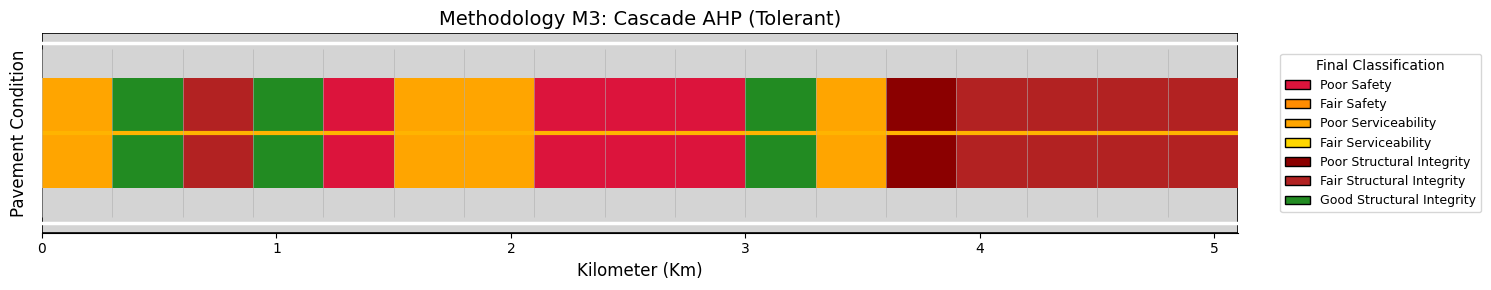

In [30]:
graficar_metodologia3_un_sentido(df_resultados_ida_m3, longitud_total_km, colores_met3,
                                nombre_archivo="MET-3.png",
                                titulo="Methodology M3: Cascade AHP (Tolerant)")




Vuelta

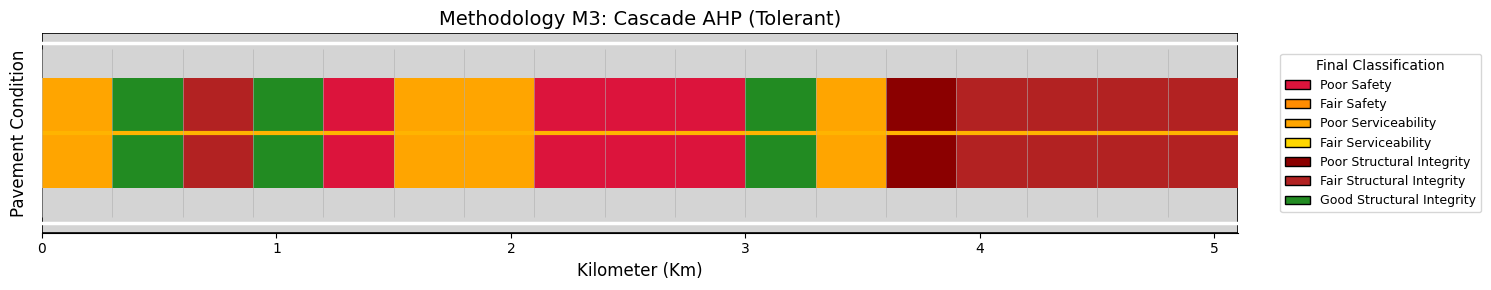

In [31]:
graficar_metodologia3_un_sentido(df_resultados_vuelta_m3, longitud_total_km, colores_met3,
                                nombre_archivo="metodologia3_vuelta_un_sentido.png",
                                titulo="Methodology M3: Cascade AHP (Tolerant)")

###Autopista

In [32]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib import colors as mcolors

def graficar_autopista_dos_cuerpos_met3(df_resultados_ida_m3,
                                       df_resultados_vuelta_m3,
                                       longitud_total_km,
                                       colores_met3,
                                       longitud_losa_m=300,
                                       alpha_banda=0.45,
                                       nombre_archivo="metodologia3_autopista_dos_cuerpos.png",
                                       titulo="Methodology M3: Cascade AHP (Tolerant)"):
    """
    Dibuja autopista de dos cuerpos (IDA abajo, VUELTA arriba) usando Clasif_Final_Homogenea.
    Requiere columnas: KM_Inicio, KM_Fin, Clasif_Final_Homogenea
    """

    # Blindaje texto
    df_ida = df_resultados_ida_m3.copy()
    df_vta = df_resultados_vuelta_m3.copy()
    df_ida['Clasif_Final_Homogenea'] = df_ida['Clasif_Final_Homogenea'].astype(str).str.strip()
    df_vta['Clasif_Final_Homogenea'] = df_vta['Clasif_Final_Homogenea'].astype(str).str.strip()

    for dfx in [df_ida, df_vta]:
        dfx["KM_Inicio"] = dfx["KM_Inicio"].apply(km_estacado_a_km)
        dfx["KM_Fin"]    = dfx["KM_Fin"].apply(km_estacado_a_km)

    max_km = float(max(df_ida["KM_Fin"].max(), df_vta["KM_Fin"].max()))

    body_height = 0.8
    gap = 0.25
    y_base_ida = 0.0
    y_base_vuelta = body_height + gap

    plt.figure(figsize=(15, 4))
    ax = plt.gca()

    # 1) Cuerpos gris
    for y0 in [y_base_ida, y_base_vuelta]:
        carretera = mpatches.Rectangle(
            (0, y0), max_km, body_height,
            facecolor="#D4D4D4", edgecolor='black', linewidth=1.2
        )
        ax.add_patch(carretera)

    # 2) Líneas laterales
    amarillo = "#FFB400"

    # IDA: exterior blanca abajo, camellón amarilla arriba
    ax.plot([0, max_km], [y_base_ida + 0.05, y_base_ida + 0.05], color='white', linewidth=2.5)
    ax.plot([0, max_km], [y_base_ida + body_height - 0.05, y_base_ida + body_height - 0.05],
            color=amarillo, linewidth=3.0)

    # VUELTA: camellón amarilla abajo, exterior blanca arriba
    ax.plot([0, max_km], [y_base_vuelta + 0.05, y_base_vuelta + 0.05], color=amarillo, linewidth=3.0)
    ax.plot([0, max_km], [y_base_vuelta + body_height - 0.05, y_base_vuelta + body_height - 0.05],
            color='white', linewidth=2.5)

    # 3) Línea entre carriles (discontinua)
    for y0 in [y_base_ida, y_base_vuelta]:
        ax.plot([0, max_km], [y0 + body_height/2, y0 + body_height/2],
                color='white', linewidth=1.5, linestyle='--')

    # 4) Juntas de losas
    losa_km = longitud_losa_m / 1000.0
    x = 0.0
    while x <= max_km + losa_km:
        for y0 in [y_base_ida, y_base_vuelta]:
            ax.vlines(x, y0 + 0.07, y0 + body_height - 0.07, colors='#B0B0B0', linewidth=0.4)
        x += losa_km

    # 5) Bandas de severidad
    band_height = body_height * 0.6
    band_offset = (body_height - band_height) / 2

    # IDA
    for _, row in df_ida.iterrows():
        start_km = km_estacado_a_km(row['KM_Inicio'])
        end_km   = km_estacado_a_km(row['KM_Fin'])
        if np.isnan(start_km) or np.isnan(end_km):
            continue
        width_km = max(end_km - start_km, 0.0)

        clasif = str(row['Clasif_Final_Homogenea']).strip()
        color_hex = colores_met3.get(clasif, "#AAAAAA")
        r, g, b = mcolors.to_rgb(color_hex)

        rect = mpatches.Rectangle(
            (start_km, y_base_ida + band_offset), width_km, band_height,
            facecolor=(r, g, b, 1.0), edgecolor='none'
        )
        ax.add_patch(rect)

    # VUELTA
    for _, row in df_vta.iterrows():
        start_km = km_estacado_a_km(row['KM_Inicio'])
        end_km   = km_estacado_a_km(row['KM_Fin'])
        if np.isnan(start_km) or np.isnan(end_km):
            continue
        width_km = max(end_km - start_km, 0.0)

        clasif = str(row['Clasif_Final_Homogenea']).strip()
        color_hex = colores_met3.get(clasif, "#AAAAAA")
        r, g, b = mcolors.to_rgb(color_hex)

        rect = mpatches.Rectangle(
            (start_km, y_base_vuelta + band_offset), width_km, band_height,
            facecolor=(r, g, b, 1.0), edgecolor='none'
        )
        ax.add_patch(rect)

    # 6) Ejes
    ax.set_xlim(0, max_km)
    ax.set_ylim(-0.1, y_base_vuelta + body_height + 0.1)
    ax.set_yticks([])
    ax.set_xlabel("Kilómetro", fontsize=12)
    plt.xticks(np.arange(0, max_km, 1.0), fontsize=10)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.spines['bottom'].set_visible(True)

    ax.set_title(titulo, fontsize=14)
    ax.set_ylabel("Estado del tramo", fontsize=12, labelpad=10)

    # 7) Leyenda
    handles = [
        mpatches.Patch(facecolor=colores_met3[label], edgecolor='black', label=label)
        for label in colores_met3.keys()
    ]
    ax.legend(handles=handles, loc='center left', bbox_to_anchor=(1.02, 0.5), fontsize=9, title="Final Classification")

    plt.tight_layout()
    #plt.savefig(nombre_archivo, dpi=300, bbox_inches="tight")
    plt.show()


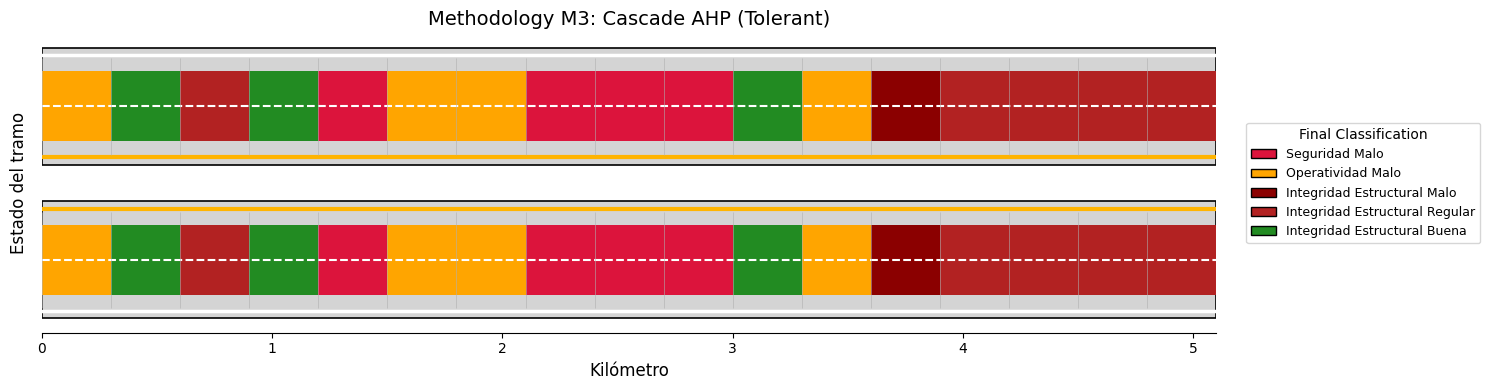

In [33]:
graficar_autopista_dos_cuerpos_met3(df_resultados_ida_m3, df_resultados_vuelta_m3,
                                   longitud_total_km, colores_met3,
                                   nombre_archivo="metodologia3_autopista_dos_cuerpos.png",
                                   titulo="Methodology M3: Cascade AHP (Tolerant)")


###Tramos

In [34]:
def contar_tramos_por_severidad(df):
    s = (df['Clasif_Final_Homogenea']
         .fillna('SIN_CLASIFICAR')
         .astype(str)
         .str.strip()
         .str.upper())

    return s.value_counts()

print(contar_tramos_por_severidad(df_resultados_ida_m3))
print(contar_tramos_por_severidad(df_resultados_vuelta_m3))

Clasif_Final_Homogenea
INTEGRIDAD ESTRUCTURAL REGULAR    5
OPERATIVIDAD MALO                 4
SEGURIDAD MALO                    4
INTEGRIDAD ESTRUCTURAL BUENA      3
INTEGRIDAD ESTRUCTURAL MALO       1
Name: count, dtype: int64
Clasif_Final_Homogenea
INTEGRIDAD ESTRUCTURAL REGULAR    5
OPERATIVIDAD MALO                 4
SEGURIDAD MALO                    4
INTEGRIDAD ESTRUCTURAL BUENA      3
INTEGRIDAD ESTRUCTURAL MALO       1
Name: count, dtype: int64


#Methodology M4: Hybrid Cascade AHP–WT–CDA (Strict)


Energía LTE: 0.24322853496658714
Energía DEF: 2.004465325576594
Factor crítico etapa 3: DEF
Clasificación etapa 3: Regular
Longitud del subtramo en etapa 3: 4
LTE normalizado: [0.0, 0.48612070013473846, 0.08315768074627172, 0.0]
DEF normalizado: [0.05839910993868236, 1.0, 0.03247875513259899, 1.0]
   KM_Inicio  KM_Fin            Origen_Final Clasificacion_Final
0        0.0     0.6            Operatividad                Malo
1        0.3     1.5  Integridad Estructural             Regular
2        0.3     1.5  Integridad Estructural             Regular
3        0.3     1.5  Integridad Estructural             Regular
4        1.2     2.1            Operatividad                Malo
5        1.8     3.0               Seguridad                Malo
6        2.7     3.3               Seguridad                Malo
7        3.0     3.6               Seguridad                Malo
8        3.3     4.8               Seguridad             Regular
9        4.5     5.1            Operatividad       

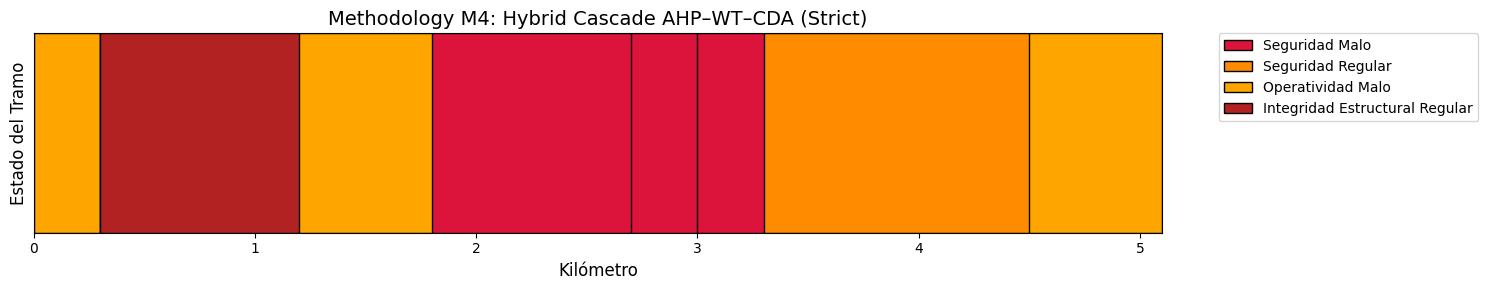

In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import pywt

# ============================================================
# METODOLOGÍA 4 (Wavelet + Diferencias Acumuladas) - ESTRICTA
# Seguridad (CF/TX) -> solo BUENO avanza
# Operatividad (IRI/JF) -> solo BUENO avanza
# Integridad (LTE/DEF) -> final
# ============================================================

# ==================== 3. FUNCIONES AUXILIARES ====================

def normalizar(valor, indicador, umbrales_dict=umbrales):
    """
    Normaliza a [0,1]:
      0 = condición buena / óptima
      1 = condición mala
    """
    if pd.isna(valor):
        return np.nan

    config = umbrales_dict.get(indicador)
    if not config:
        raise ValueError(f"Umbrales no definidos para: {indicador}")

    # Menor es mejor
    if indicador in ['IRI', 'JF', 'DEF']:
        X_min_bueno = config['Bueno'][0]
        X_limite_malo = config['Malo'][0]  # inicio de Malo
        if valor <= X_min_bueno:
            return 0.0
        if valor >= X_limite_malo:
            return 1.0
        if X_limite_malo == X_min_bueno:
            return 0.0
        return float((valor - X_min_bueno) / (X_limite_malo - X_min_bueno))

    # Mayor es mejor
    elif indicador in ['LTE', 'TX']:
        X_min_bueno = config['Bueno'][0]
        X_limite_malo = config['Malo'][1]  # tope superior de Malo
        if valor >= X_min_bueno:
            return 0.0
        if valor <= X_limite_malo:
            return 1.0
        if X_min_bueno == X_limite_malo:
            return 0.0
        return float((X_min_bueno - valor) / (X_min_bueno - X_limite_malo))

    # CF: óptimo intermedio (Bueno es un intervalo)
    elif indicador == 'CF':
        opt_min, opt_max = config['Bueno']          # (0.61, 0.90)
        malo_bajo_lim = config['Malo_Bajo'][1]      # 0.40
        malo_alto_lim = config['Malo_Alto'][0]      # 0.90

        # Óptimo
        if opt_min <= valor <= opt_max:
            return 0.0

        # Bajo (hacia Malo_Bajo)
        if valor < opt_min:
            den = (opt_min - malo_bajo_lim)
            if den == 0:
                return 1.0
            return float(np.clip((opt_min - valor) / den, 0.0, 1.0))

        # Alto (hacia Malo_Alto)
        den = (malo_alto_lim - opt_max)
        if den == 0:
            return 1.0
        return float(np.clip((valor - opt_max) / den, 0.0, 1.0))

    # Si llega aquí, no se definió: no penalizar
    return 0.0


def clasificar_valor(valor, indicador, umbrales_dict=umbrales):
    """
    Clasifica: 'Bueno', 'Regular' o 'Malo' según umbrales.
    Evita 'Desconocido' en CF por huecos (0.60–0.61).
    """
    if pd.isna(valor):
        return "N/A"

    u = umbrales_dict.get(indicador)
    if not u:
        return "Desconocido"

    # Menor es mejor
    if indicador in ['IRI', 'JF', 'DEF']:
        if valor <= u['Bueno'][1]:
            return 'Bueno'
        elif valor <= u['Regular'][1]:
            return 'Regular'
        else:
            return 'Malo'

    # Mayor es mejor
    elif indicador in ['LTE', 'TX']:
        if valor >= u['Bueno'][0]:
            return 'Bueno'
        elif valor >= u['Regular'][0]:
            return 'Regular'
        else:
            return 'Malo'

    # CF: óptimo intermedio (SIN HUECOS)
    elif indicador == 'CF':
        b0, b1 = u['Bueno']        # (0.61, 0.90)
        r0, r1 = u['Regular']      # (0.41, 0.60)
        mb1 = u['Malo_Bajo'][1]    # 0.40
        ma0 = u['Malo_Alto'][0]    # 0.90

        # Malo fuera del rango seguro (bajo o alto)
        if valor < mb1 or valor >= ma0:
            return 'Malo'

        # Bueno: rango óptimo
        if b0 <= valor < b1:
            return 'Bueno'

        # Regular: incluye el hueco (r1..b0)
        if r0 <= valor < b0:
            return 'Regular'

        # Respaldo por redondeos
        return 'Regular'

    return "Desconocido"


def calcular_energia_wavelet(serie_normalizada, wavelet_type='haar', wavelet_level=1):
    """
    Energía total de coeficientes wavelet usando Haar nivel 1.
    Adecuada para subtramos cortos.
    """
    s = pd.Series(serie_normalizada).astype(float)

    if s.isna().all():
        return 0.0

    s = s.interpolate(limit_direction="both").ffill().bfill()
    x = s.values

    w = pywt.Wavelet(wavelet_type)

    # Validación mínima según la longitud del filtro de la wavelet
    if len(x) < w.dec_len:
        return 0.0

    max_level = pywt.dwt_max_level(data_len=len(x), filter_len=w.dec_len)
    level = min(int(wavelet_level), int(max_level))

    if level <= 0:
        return 0.0

    coeffs = pywt.wavedec(x, wavelet_type, level=level)
    energia_total = sum(np.sum(np.square(c)) for c in coeffs)

    energia_total = float(energia_total)
    if abs(energia_total) < 1e-12:
        energia_total = 0.0

    return energia_total


def calcular_diferencias_acumuladas(data_series, k_factor=0.25):
    """
    Método CD/CUSUM-like para segmentación.
    - Interpola NaNs.
    - Detecta extremos locales del CD y filtra por salto mínimo k_factor.
    """
    if data_series is None or len(data_series) < 2:
        return []

    s = pd.Series(data_series).astype(float)
    if s.isna().all():
        return []

    s = s.interpolate(limit_direction="both").ffill().bfill()

    mean_val = s.mean()
    std_dev = s.std(ddof=0)

    if std_dev == 0 or np.isnan(std_dev):
        return [{
            'start_idx': s.index[0],
            'end_idx': s.index[-1],
            'mean_value': float(mean_val)
        }]

    z = (s - mean_val) / std_dev
    cd = z.cumsum()

    d1 = cd.diff()
    sign = np.sign(d1).replace(0, np.nan).ffill().bfill()
    extremos = cd.index[(sign.shift(-1) != sign) & (sign.notna())]

    change_points = [cd.index[0]]
    last_cp = change_points[-1]

    for idx in extremos:
        if idx == last_cp:
            continue
        if abs(cd.loc[idx] - cd.loc[last_cp]) >= k_factor:
            change_points.append(idx)
            last_cp = idx

    if cd.index[-1] not in change_points:
        change_points.append(cd.index[-1])

    change_points = sorted(set(change_points))

    homogeneous_sections = []
    for i in range(len(change_points) - 1):
        start_index = change_points[i]
        end_index = change_points[i + 1]
        section_data = s.loc[start_index:end_index]
        if not section_data.empty:
            homogeneous_sections.append({
                'start_idx': start_index,
                'end_idx': end_index,
                'mean_value': float(section_data.mean())
            })

    return homogeneous_sections

# ==================== 4. FUNCIÓN PRINCIPAL METODOLOGÍA 4 ====================

def analizar_tramo_jerarquico_rigido_met4(df, umbrales, k_factor_cd=0.25, wavelet_level=1):
    energia_lte = None
    energia_def = None
    critical_factor = None
    status = None
    subset_df = None
    lte_norm = None
    def_norm = None
    """
    METODOLOGÍA 4 (estricta):
      1) Seguridad: CF vs TX
      2) Operatividad: IRI vs JF
      3) Integridad estructural: LTE vs DEF

    - En cada nivel: se elige el factor con mayor energía wavelet.
    - Segmentación con CD.
    - SOLO BUENOS avanzan al siguiente nivel.
    """
    df_result = df.copy()

    df_result["KM_Inicio"] = df_result["KM_Inicio"].apply(km_estacado_a_km)
    df_result["KM_Fin"]    = df_result["KM_Fin"].apply(km_estacado_a_km)

    # Normalizar todos los indicadores
    for col in ['IRI', 'JF', 'LTE', 'DEF', 'CF', 'TX']:
        df_result[f'{col}_Normalizado'] = df_result[col].apply(lambda x: normalizar(x, col, umbrales))

    sections_to_process = [{
        'start_idx': df_result.index[0],
        'end_idx': df_result.index[-1],
        'prev_info': {}
    }]

    final_homogeneous_sections = []

    # ---------- ETAPA 1: SEGURIDAD (CF vs TX) ----------
    next_stage_sections = []

    for section in sections_to_process:
        subset_df = df_result.loc[section['start_idx']:section['end_idx']]
        if subset_df.empty:
            continue

        cf_norm = subset_df['CF_Normalizado']
        tx_norm = subset_df['TX_Normalizado']

        energia_cf = calcular_energia_wavelet(cf_norm, wavelet_level=wavelet_level)
        energia_tx = calcular_energia_wavelet(tx_norm, wavelet_level=wavelet_level)
####    #
        if energia_cf >= energia_tx:
            critical_factor = 'CF'
            energia_segmentacion = energia_cf
            series_for_cd = cf_norm
        else:
            critical_factor = 'TX'
            energia_segmentacion = energia_tx
            series_for_cd = tx_norm

        cd_sections = calcular_diferencias_acumuladas(series_for_cd, k_factor=k_factor_cd)
        if not cd_sections:
            cd_sections = [{
                'start_idx': section['start_idx'],
                'end_idx': section['end_idx'],
                'mean_value': float(pd.Series(series_for_cd).astype(float).mean())
            }]

        for cd_sec in cd_sections:
            sec_start_idx = cd_sec['start_idx']
            sec_end_idx = cd_sec['end_idx']

            mean_original_value = float(df_result.loc[sec_start_idx:sec_end_idx, critical_factor].mean())
            status = clasificar_valor(mean_original_value, critical_factor, umbrales)

            section_info = {
                'KM_Inicio_Idx': sec_start_idx,
                'KM_Fin_Idx': sec_end_idx,
                'KM_Inicio': float(df_result.loc[sec_start_idx, 'KM_Inicio']),
                'KM_Fin': float(df_result.loc[sec_end_idx, 'KM_Fin']),
                'Factor_Etapa_1': critical_factor,
                'Valor_Original_Etapa_1': mean_original_value,
                'Valor_Normalizado_Etapa_1': float(cd_sec['mean_value']),
                'Clasificacion_Etapa_1': status,
                'Critico_Etapa_1': critical_factor,
                'Energia_Segmentacion_Etapa_1': energia_segmentacion
            }

            if status == 'Bueno':
                next_stage_sections.append({
                    'start_idx': sec_start_idx,
                    'end_idx': sec_end_idx,
                    'prev_info': section_info
                })
            else:
                section_info['Origen_Final'] = 'Seguridad'
                section_info['Clasificacion_Final'] = status
                section_info['Motivo_Clasificacion_Final'] = f"Detenido en Etapa 1 (Seguridad: {critical_factor}, {status})"
                final_homogeneous_sections.append(section_info)

    sections_to_process = next_stage_sections
    next_stage_sections = []

    # ---------- ETAPA 2: OPERATIVIDAD (IRI vs JF) ----------
    for section in sections_to_process:
        subset_df = df_result.loc[section['start_idx']:section['end_idx']]
        if subset_df.empty:
            info = section['prev_info']
            info['Origen_Final'] = 'Operatividad'
            info['Clasificacion_Final'] = 'N/A'
            info['Motivo_Clasificacion_Final'] = "Detenido en Etapa 2 (sin datos)"
            final_homogeneous_sections.append(info)
            continue

        iri_norm = subset_df['IRI_Normalizado']
        jf_norm = subset_df['JF_Normalizado']

        energia_iri = calcular_energia_wavelet(iri_norm, wavelet_level=wavelet_level)
        energia_jf = calcular_energia_wavelet(jf_norm, wavelet_level=wavelet_level)
        #
        if energia_iri >= energia_jf:
            critical_factor = 'IRI'
            energia_segmentacion = energia_iri
            series_for_cd = iri_norm
        else:
            critical_factor = 'JF'
            energia_segmentacion = energia_jf
            series_for_cd = jf_norm

        cd_sections = calcular_diferencias_acumuladas(series_for_cd, k_factor=k_factor_cd)
        if not cd_sections:
            cd_sections = [{
                'start_idx': section['start_idx'],
                'end_idx': section['end_idx'],
                'mean_value': float(pd.Series(series_for_cd).astype(float).mean())
            }]

        for cd_sec in cd_sections:
            sec_start_idx = cd_sec['start_idx']
            sec_end_idx = cd_sec['end_idx']

            mean_original_value = float(df_result.loc[sec_start_idx:sec_end_idx, critical_factor].mean())
            status = clasificar_valor(mean_original_value, critical_factor, umbrales)

            current_section_info = section['prev_info'].copy()
            current_section_info.update({
                'Factor_Etapa_2': critical_factor,
                'Valor_Original_Etapa_2': mean_original_value,
                'Valor_Normalizado_Etapa_2': float(cd_sec['mean_value']),
                'Clasificacion_Etapa_2': status,
                'Critico_Etapa_2': critical_factor,
                'Energia_Segmentacion_Etapa_2': energia_segmentacion
            })

            if status == 'Bueno':
                next_stage_sections.append({
                    'start_idx': sec_start_idx,
                    'end_idx': sec_end_idx,
                    'prev_info': current_section_info
                })
            else:
                current_section_info['Origen_Final'] = 'Operatividad'
                current_section_info['Clasificacion_Final'] = status
                current_section_info['Motivo_Clasificacion_Final'] = f"Detenido en Etapa 2 (Operatividad: {critical_factor}, {status})"
                final_homogeneous_sections.append(current_section_info)

    sections_to_process = next_stage_sections

    # ---------- ETAPA 3: INTEGRIDAD ESTRUCTURAL (LTE vs DEF) ----------
    for section in sections_to_process:
        subset_df = df_result.loc[section['start_idx']:section['end_idx']]
        if subset_df.empty:
            info = section['prev_info']
            info['Origen_Final'] = 'Integridad Estructural'
            info['Clasificacion_Final'] = 'N/A'
            info['Motivo_Clasificacion_Final'] = "Detenido en Etapa 3 (sin datos)"
            final_homogeneous_sections.append(info)
            continue

        lte_norm = subset_df['LTE_Normalizado']
        def_norm = subset_df['DEF_Normalizado']

        energia_lte = calcular_energia_wavelet(lte_norm, wavelet_level=wavelet_level)
        energia_def = calcular_energia_wavelet(def_norm, wavelet_level=wavelet_level)
        #
        if energia_lte >= energia_def:
            critical_factor = 'LTE'
            energia_segmentacion = energia_lte
            series_for_cd = lte_norm
        else:
            critical_factor = 'DEF'
            energia_segmentacion = energia_def
            series_for_cd = def_norm

        cd_sections = calcular_diferencias_acumuladas(series_for_cd, k_factor=k_factor_cd)
        if not cd_sections:
            cd_sections = [{
                'start_idx': section['start_idx'],
                'end_idx': section['end_idx'],
                'mean_value': float(pd.Series(series_for_cd).astype(float).mean())
            }]

        for cd_sec in cd_sections:
            sec_start_idx = cd_sec['start_idx']
            sec_end_idx = cd_sec['end_idx']

            mean_original_value = float(df_result.loc[sec_start_idx:sec_end_idx, critical_factor].mean())
            status = clasificar_valor(mean_original_value, critical_factor, umbrales)

            current_section_info = section['prev_info'].copy()
            current_section_info.update({
                'Factor_Etapa_3': critical_factor,
                'Valor_Original_Etapa_3': mean_original_value,
                'Valor_Normalizado_Etapa_3': float(cd_sec['mean_value']),
                'Clasificacion_Etapa_3': status,
                'Critico_Etapa_3': critical_factor,
                'Energia_Segmentacion_Etapa_3': energia_segmentacion
            })

            current_section_info['Origen_Final'] = 'Integridad Estructural'
            current_section_info['Clasificacion_Final'] = status
            current_section_info['Motivo_Clasificacion_Final'] = f"Finalizada en Etapa 3 (Integridad: {critical_factor}, {status})"
            final_homogeneous_sections.append(current_section_info)

    if energia_lte is not None:
        print("Energía LTE:", energia_lte)
        print("Energía DEF:", energia_def)
        print("Factor crítico etapa 3:", critical_factor)
        print("Clasificación etapa 3:", status)
        print("Longitud del subtramo en etapa 3:", len(subset_df))
        print("LTE normalizado:", list(lte_norm))
        print("DEF normalizado:", list(def_norm))
    else:
        print("No se ejecutó la etapa 3; no hubo cálculo de energías LTE/DEF.")

    df_final_sections = pd.DataFrame(final_homogeneous_sections).sort_values(by='KM_Inicio').reset_index(drop=True)

    # Garantizar columnas de etapa
    for i in range(1, 4):
        for base in [
            'Clasificacion_Etapa_', 'Critico_Etapa_', 'Factor_Etapa_',
            'Valor_Original_Etapa_', 'Valor_Normalizado_Etapa_'
        ]:
            col = f"{base}{i}"
            if col not in df_final_sections.columns:
                df_final_sections[col] = np.nan

    return df_final_sections


# ==================== 6. VISUALIZACIÓN SUMARIA ====================

def plot_homogeneous_sections_summary_met4(df_sections, longitud_total_km, titulo=None):
    fig, ax = plt.subplots(figsize=(15, 3))

    color_map = {
        "Seguridad Malo":                 '#DC143C',
        "Seguridad Regular":              '#FF8C00',
        "Operatividad Malo":              '#FFA500',
        "Operatividad Regular":           '#FFD700',
        "Integridad Estructural Malo":    '#8B0000',
        "Integridad Estructural Regular": '#B22222',
        "Integridad Estructural Bueno":   '#228B22',
        # opcional por si sale:
        "Seguridad N/A":                  '#A9A9A9',
        "Operatividad N/A":               '#A9A9A9',
        "Integridad Estructural N/A":     '#A9A9A9',
        "Seguridad Desconocido":          '#A9A9A9',
        "Operatividad Desconocido":       '#A9A9A9',
        "Integridad Estructural Desconocido": '#A9A9A9',
    }

    for _, row in df_sections.iterrows():
        start_km = float(row['KM_Inicio'])
        end_km = float(row['KM_Fin'])

        origen = str(row.get('Origen_Final', 'Desconocido')).strip()
        clasif = str(row.get('Clasificacion_Final', 'Desconocido')).strip()
        label = f"{origen} {clasif}"
        color = color_map.get(label, '#A9A9A9')

        rect = mpatches.Rectangle(
            (start_km, 0),
            end_km - start_km,
            1,
            facecolor=color,
            edgecolor='black',
            linewidth=1
        )
        ax.add_patch(rect)

    ax.set_xlim(0, float(df_sections['KM_Fin'].max()))
    ax.set_ylim(0, 1)
    ax.set_yticks([])
    ax.set_xlabel('Kilómetro', fontsize=12)
    ax.set_ylabel('Estado del Tramo', fontsize=12)

    if titulo is None:
        titulo = 'Methodology M4: Hybrid Cascade AHP–WT–CDA (Strict)'
    ax.set_title(titulo, fontsize=14)

    ax.grid(False)
    plt.xticks(np.arange(0, longitud_total_km + 1, 1.0))

    # Leyenda en el orden que pediste
    orden_leyenda = [
        "Seguridad Malo",
        "Seguridad Regular",
        "Operatividad Malo",
        "Operatividad Regular",
        "Integridad Estructural Malo",
        "Integridad Estructural Regular",
        "Integridad Estructural Bueno"
    ]

    labels_presentes = {
        f"{str(r.get('Origen_Final','')).strip()} {str(r.get('Clasificacion_Final','')).strip()}"
        for _, r in df_sections.iterrows()
    }

    handles = [
        mpatches.Patch(facecolor=color_map[lbl], edgecolor='black', label=lbl)
        for lbl in orden_leyenda
        if lbl in labels_presentes
    ]

    if handles:
        ax.legend(handles=handles, bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)

    plt.tight_layout()
    plt.show()


# ==================== 7. EJECUCIÓN ====================

secciones_homogeneas_ida = analizar_tramo_jerarquico_rigido_met4(df_tramo_ida, umbrales, k_factor_cd=0.25, wavelet_level=1)
print(secciones_homogeneas_ida[['KM_Inicio','KM_Fin','Origen_Final','Clasificacion_Final']])

secciones_homogeneas_vuelta = analizar_tramo_jerarquico_rigido_met4(df_tramo_vuelta, umbrales, k_factor_cd=0.25, wavelet_level=1)
print(secciones_homogeneas_vuelta[['KM_Inicio','KM_Fin','Origen_Final','Clasificacion_Final']])

plot_homogeneous_sections_summary_met4(
    secciones_homogeneas_ida,
    longitud_total_km=longitud_total_km,
    titulo="Methodology M4: Hybrid Cascade AHP–WT–CDA (Strict)"
)



In [36]:
print("Promedios globales:")
print("CF mean:", df_tramo_vuelta["CF"].mean())
print("TX mean:", df_tramo_vuelta["TX"].mean())

cf_status = clasificar_valor(df_tramo_vuelta["CF"].mean(), "CF", umbrales)
tx_status = clasificar_valor(df_tramo_vuelta["TX"].mean(), "TX", umbrales)

print("Clasif CF global:", cf_status)
print("Clasif TX global:", tx_status)

# ver qué factor está ganando por energía wavelet en Seguridad
df_tmp = df_tramo_vuelta.copy()
df_tmp["CF_Normalizado"] = df_tmp["CF"].apply(lambda x: normalizar(x, "CF", umbrales))
df_tmp["TX_Normalizado"] = df_tmp["TX"].apply(lambda x: normalizar(x, "TX", umbrales))

e_cf = calcular_energia_wavelet(df_tmp["CF_Normalizado"], wavelet_level=1)
e_tx = calcular_energia_wavelet(df_tmp["TX_Normalizado"], wavelet_level=1)

print("Energia CF:", e_cf, "Energia TX:", e_tx)
print("Factor crítico elegido:", "CF" if e_cf >= e_tx else "TX")


Promedios globales:
CF mean: 0.5346405656986558
TX mean: 0.8359852949230684
Clasif CF global: Regular
Clasif TX global: Regular
Energia CF: 8.80105253742172 Energia TX: 7.036178415806027
Factor crítico elegido: CF


In [37]:
import numpy as np
import pandas as pd

def fusionar_tramos_homogeneos(df, tol=1e-6):
    """
    Fusiona tramos si tienen el MISMO (Origen_Final, Clasificacion_Final)
    y son contiguos o se traslapan.
    """
    df2 = df.sort_values(["KM_Inicio", "KM_Fin"]).reset_index(drop=True)

    out = []
    cur = df2.loc[0].to_dict()

    for i in range(1, len(df2)):
        row = df2.loc[i]

        mismo_estado = (
            str(row["Origen_Final"]).strip() == str(cur["Origen_Final"]).strip()
            and str(row["Clasificacion_Final"]).strip() == str(cur["Clasificacion_Final"]).strip()
        )

        # contiguo o traslape (row inicia antes o muy pegado al fin del actual)
        contiguo_o_traslape = row["KM_Inicio"] <= cur["KM_Fin"] + tol

        if mismo_estado and contiguo_o_traslape:
            # extender el fin al máximo
            cur["KM_Fin"] = max(cur["KM_Fin"], row["KM_Fin"])
        else:
            out.append(cur)
            cur = row.to_dict()

    out.append(cur)
    return pd.DataFrame(out)


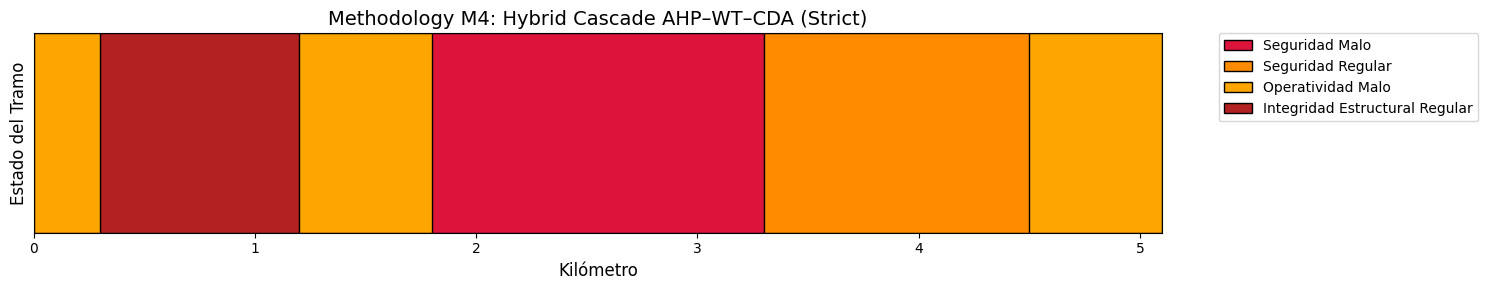

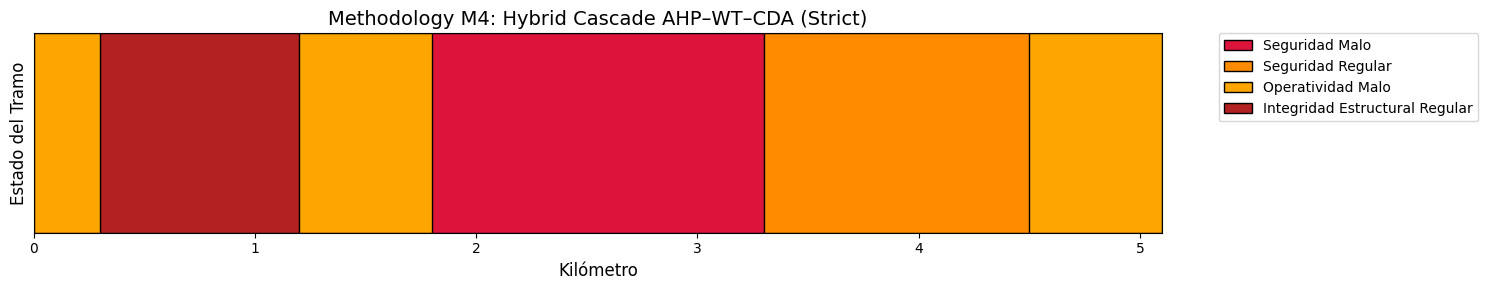

In [38]:
secciones_fusionadas_ida = fusionar_tramos_homogeneos(secciones_homogeneas_ida)
plot_homogeneous_sections_summary_met4(
    secciones_fusionadas_ida,
    longitud_total_km,
    titulo="Methodology M4: Hybrid Cascade AHP–WT–CDA (Strict)"
)

secciones_fusionadas_vuelta = fusionar_tramos_homogeneos(secciones_homogeneas_vuelta)
plot_homogeneous_sections_summary_met4(
    secciones_fusionadas_ida,
    longitud_total_km,
    titulo="Methodology M4: Hybrid Cascade AHP–WT–CDA (Strict)"
)

##Larguillo

###Autopista

In [39]:
from matplotlib import colors as mcolors
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np


def graficar_autopista_met4(df_ida, df_vuelta, longitud_total_km, titulo="Methodology M4: Hybrid Cascade AHP–WT–CDA (Strict)"):

    max_km = float(max(df_ida["KM_Fin"].max(), df_vuelta["KM_Fin"].max()))

    body_height = 0.8
    gap = 0.25
    y_ida = 0.0
    y_vuelta = body_height + gap

    fig, ax = plt.subplots(figsize=(15, 4))
    ax.set_title(titulo, fontsize=14)

    # ===== 1. Fondo gris (concreto) =====
    for y0 in [y_ida, y_vuelta]:
        ax.add_patch(
            mpatches.Rectangle(
                (0, y0), max_km, body_height,
                facecolor="#D4D4D4",
                edgecolor="black",
                linewidth=1.2
            )
        )

    # ===== 2. Líneas laterales =====
    amarillo = "#FFB400"

    # IDA
    ax.plot([0, max_km], [y_ida + 0.05]*2, color="white", linewidth=2.5)
    ax.plot([0, max_km], [y_ida + body_height - 0.05]*2, color=amarillo, linewidth=3)

    # VUELTA
    ax.plot([0, max_km], [y_vuelta + 0.05]*2, color=amarillo, linewidth=3)
    ax.plot([0, max_km], [y_vuelta + body_height - 0.05]*2, color="white", linewidth=2.5)

    # ===== 3. Línea central discontinua =====
    for y0 in [y_ida, y_vuelta]:
        ax.plot(
            [0, max_km],
            [y0 + body_height / 2]*2,
            color="white",
            linewidth=1.5,
            linestyle="--"
        )

    # ===== 4. Bandas de severidad =====
    band_height = body_height * 0.6
    band_offset = (body_height - band_height) / 2

    # --- IDA ---
    for _, row in df_ida.iterrows():
        label = f"{row['Origen_Final']} {row['Clasificacion_Final']}".strip()
        color_base = colores_met4.get(label, "#AAAAAA")
        r, g, b = mcolors.to_rgb(color_base)

        ax.add_patch(
            mpatches.Rectangle(
                (row["KM_Inicio"], y_ida + band_offset),
                row["KM_Fin"] - row["KM_Inicio"],
                band_height,
                facecolor=(r, g, b, 1.0),
                edgecolor="none"
            )
        )

    # --- VUELTA ---
    for _, row in df_vuelta.iterrows():
        label = f"{row['Origen_Final']} {row['Clasificacion_Final']}".strip()
        color_base = colores_met4.get(label, "#AAAAAA")
        r, g, b = mcolors.to_rgb(color_base)

        ax.add_patch(
            mpatches.Rectangle(
                (row["KM_Inicio"], y_vuelta + band_offset),
                row["KM_Fin"] - row["KM_Inicio"],
                band_height,
                facecolor=(r, g, b, 1.0),
                edgecolor="none"
            )
        )

    # ===== 4. JUNTAS DE LOSAS DE CONCRETO =====
    longitud_losa_m = 300      # ajusta si quieres (ej. 4.5 m, 50 m, 100 m)
    longitud_losa_km = longitud_losa_m / 1000.0

    x = 0.0
    while x <= max_km + longitud_losa_km:
        for y0 in [y_ida, y_vuelta]:
            ax.vlines(
                x,
                y0 + 0.07,
                y0 + body_height - 0.07,
                colors="#B0B0B0",   # gris concreto
                linewidth=0.4,
                alpha=0.5
            )
        x += longitud_losa_km

    # ===== 6. Ejes =====
    ax.set_xlim(0, max_km)
    ax.set_ylim(-0.1, y_vuelta + body_height + 0.1)
    ax.set_yticks([])
    ax.set_xlabel("Kilómetro", fontsize=12)
    ax.set_ylabel("Estado del tramo", fontsize=12)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)
    ax.spines["bottom"].set_visible(True)

    plt.xticks(np.arange(0, max_km, 1.0))

    ax.set_title(
        titulo,
        fontsize=14
    )

    # ===== 7. Leyenda (mostrar TODOS los colores) =====
    orden_leyenda = [
        "Seguridad Malo",
        "Seguridad Regular",
        "Operatividad Malo",
        "Operatividad Regular",
        "Integridad Estructural Malo",
        "Integridad Estructural Regular",
        "Integridad Estructural Bueno",
    ]

    handles = [
        mpatches.Patch(
            facecolor=colores_met4.get(lbl, "#AAAAAA"),
            edgecolor="black",
            label=lbl
        )
        for lbl in orden_leyenda
    ]

    ax.legend(
        handles=handles,
        loc="center left",
        bbox_to_anchor=(1.02, 0.5),
        fontsize=9,
        title="Final Classification"
    )

    plt.tight_layout()
    plt.show()



In [40]:
colores_met4 = {
    "Seguridad Malo":                 "#DC143C",  # Crimson
    "Seguridad Regular":              "#FF8C00",  # DarkOrange
    "Operatividad Malo":              "#FFA500",  # Orange
    "Operatividad Regular":           "#FFD700",  # Gold
    "Integridad Estructural Malo":    "#8B0000",  # Dark Red
    "Integridad Estructural Regular": "#B22222",  # Firebrick
    "Integridad Estructural Bueno":   "#228B22"   # Verde
}


In [41]:
# Fusión de tramos – IDA
secciones_fusionadas_ida = fusionar_tramos_homogeneos(
    secciones_homogeneas_ida
)

# Fusión de tramos – VUELTA
secciones_fusionadas_vuelta = fusionar_tramos_homogeneos(
    secciones_homogeneas_vuelta
)


Energía LTE: 0.24322853496658714
Energía DEF: 2.004465325576594
Factor crítico etapa 3: DEF
Clasificación etapa 3: Regular
Longitud del subtramo en etapa 3: 4
LTE normalizado: [0.0, 0.48612070013473846, 0.08315768074627172, 0.0]
DEF normalizado: [0.05839910993868236, 1.0, 0.03247875513259899, 1.0]
Energía LTE: 0.24322853496658714
Energía DEF: 2.004465325576594
Factor crítico etapa 3: DEF
Clasificación etapa 3: Regular
Longitud del subtramo en etapa 3: 4
LTE normalizado: [0.0, 0.48612070013473846, 0.08315768074627172, 0.0]
DEF normalizado: [0.05839910993868236, 1.0, 0.03247875513259899, 1.0]


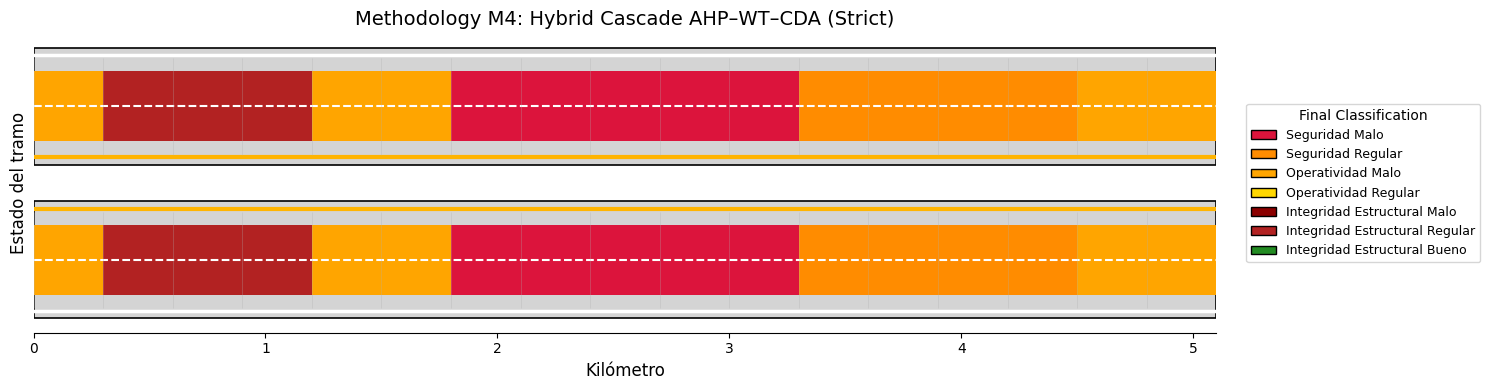

In [42]:
secciones_ida_m4    = analizar_tramo_jerarquico_rigido_met4(df_tramo_ida, umbrales,
                                                            k_factor_cd=0.25,
                                                            wavelet_level=1)
secciones_vuelta_m4 = analizar_tramo_jerarquico_rigido_met4(df_tramo_vuelta, umbrales,
                                                            k_factor_cd=0.25,
                                                            wavelet_level=1)

graficar_autopista_met4(secciones_ida_m4,
                                    secciones_vuelta_m4,
                                    longitud_total_km)


###Carretera

In [43]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib import colors as mcolors

def graficar_sentido_met4_estilo_autopista(df_secciones_fusionadas, longitud_total_km,
                                          titulo="MET-4",
                                          longitud_losa_m=300, alpha_banda=0.45):
    """
    Gráfica 1 sentido con el estilo 'autopista' (concreto + líneas + juntas + bandas).
    df_secciones_fusionadas debe traer:
      KM_Inicio, KM_Fin, Origen_Final, Clasificacion_Final
    """

    # ---- Colores (mismos que vienes usando) ----
    color_map = {
        "Poor Safety":                      '#DC143C',  # Crimson
        "Fair Safety":                      '#FF8C00',  # DarkOrange
        "Poor Serviceability":              '#FFA500',  # Orange
        "Fair Serviceability":              '#FFD700',  # Gold
        "Poor Structural Integrity":        '#8B0000',  # Dark Red
        "Fair Structural Integrity":        '#B22222',  # Firebrick
        "Good Structural Integrity":        '#228B22'   # Verde
    }

    # ---- Preparar labels ----
    df_plot = df_secciones_fusionadas.copy()
    if "Label_Final" not in df_plot.columns:
        df_plot["Label_Final"] = (
            df_plot["Origen_Final"].astype(str).str.strip() + " " +
            df_plot["Clasificacion_Final"].astype(str).str.strip()
        )

        # Mapeo de traducción
        traduccion = {
            "Seguridad Malo": "Poor Safety",
            "Seguridad Regular": "Fair Safety",
            "Operatividad Malo": "Poor Serviceability",
            "Operatividad Regular": "Fair Serviceability",
            "Integridad Estructural Malo": "Poor Structural Integrity",
            "Integridad Estructural Regular": "Fair Structural Integrity",
            "Integridad Estructural Bueno": "Good Structural Integrity"
        }
        # Aplicar la traducción a la columna que genera el label
        df_plot["Label_Final"] = (
            df_plot["Origen_Final"].astype(str).str.strip() + " " +
            df_plot["Clasificacion_Final"].astype(str).str.strip()
        ).replace(traduccion)

    for dfx in [df_ida, df_vuelta]:
        dfx["KM_Inicio"] = dfx["KM_Inicio"].apply(km_estacado_a_km)
        dfx["KM_Fin"]    = dfx["KM_Fin"].apply(km_estacado_a_km)
    max_km = float(max(df_ida["KM_Fin"].max(), df_vuelta["KM_Fin"].max()))

    body_height = 1.0

    plt.figure(figsize=(15, 3))
    ax = plt.gca()

    # ===== 1) Cuerpo gris (concreto) =====
    carretera = mpatches.Rectangle(
        (0, 0),
        max_km,
        body_height,
        facecolor="#D4D4D4",
        edgecolor='black',
        linewidth=1.2
    )
    ax.add_patch(carretera)

    # ===== 2) Líneas laterales (blancas) =====
    ax.plot([0, max_km], [0.95, 0.95], color='white', linewidth=2.5)
    ax.plot([0, max_km], [0.05, 0.05], color='white', linewidth=2.5)

    # ===== 3) Línea central continua (amarilla) =====
    ax.plot([0, max_km], [0.50, 0.50],
    color='#FFB400', linewidth=3.0, linestyle='-')

    # ===== 4) Juntas de losas =====
    longitud_losa_km = longitud_losa_m / 1000.0
    x = 0.0
    while x <= max_km + longitud_losa_km:
        ax.vlines(
            x,
            0.08, 0.92,
            colors='#B0B0B0',
            linewidth=0.4,
            linestyles='-'
        )
        x += longitud_losa_km

    # ===== 5) Banda de clasificación (semí-transparente) =====
    band_height = 0.55
    band_y = (body_height - band_height) / 2

    for _, row in df_plot.iterrows():
        start_km = float(row["KM_Inicio"])
        end_km   = float(row["KM_Fin"])
        width_km = max(0.0, end_km - start_km)

        label = str(row["Label_Final"]).strip()
        base_color = color_map.get(label, "#AAAAAA")
        r, g, b = mcolors.to_rgb(base_color)

        rect = mpatches.Rectangle(
            (start_km, band_y),
            width_km,
            band_height,
            facecolor=(r, g, b, 1.0),
            edgecolor='none'
        )
        ax.add_patch(rect)

    # ===== 6) Ejes =====
    ax.set_xlim(0, max_km)
    ax.set_ylim(0, body_height)
    ax.set_yticks([])
    ax.set_xlabel("Kilometer (Km)", fontsize=12)
    ax.set_ylabel("Pavement Condition", fontsize=12)
    plt.xticks(np.arange(0, max_km, 1.0), fontsize=10)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.spines['bottom'].set_visible(True)

    ax.set_title(titulo, fontsize=14)

    # ===== 7. Leyenda (mostrar TODOS los colores) =====
    orden_leyenda = [
        "Poor Safety",
        "Fair Safety",
        "Poor Serviceability",
        "Fair Serviceability",
        "Poor Structural Integrity",
        "Fair Structural Integrity",
        "Good Structural Integrity",
    ]

    handles = [
        mpatches.Patch(
            facecolor=color_map.get(lbl, "#AAAAAA"),
            edgecolor="black",
            label=lbl
        )
        for lbl in orden_leyenda
    ]

    ax.legend(
        handles=handles,
        loc="center left",
        bbox_to_anchor=(1.03, 0.5),
        fontsize=9,
        title="Final Classification"
    )

    plt.tight_layout()
    plt.savefig("MET-4", dpi=300, bbox_inches="tight")
    plt.show()


Ida

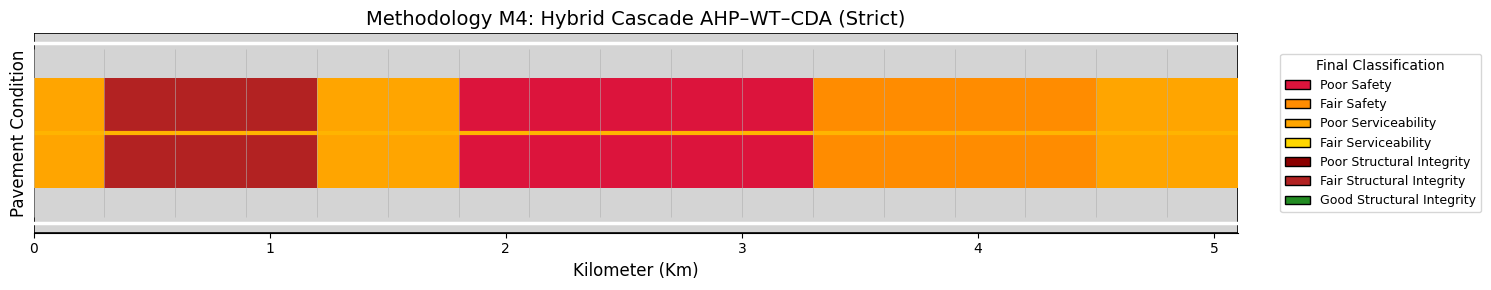

In [44]:
# IDA
graficar_sentido_met4_estilo_autopista(
    secciones_fusionadas_ida,
    longitud_total_km,
    titulo="Methodology M4: Hybrid Cascade AHP–WT–CDA (Strict)"
)



Vuelta

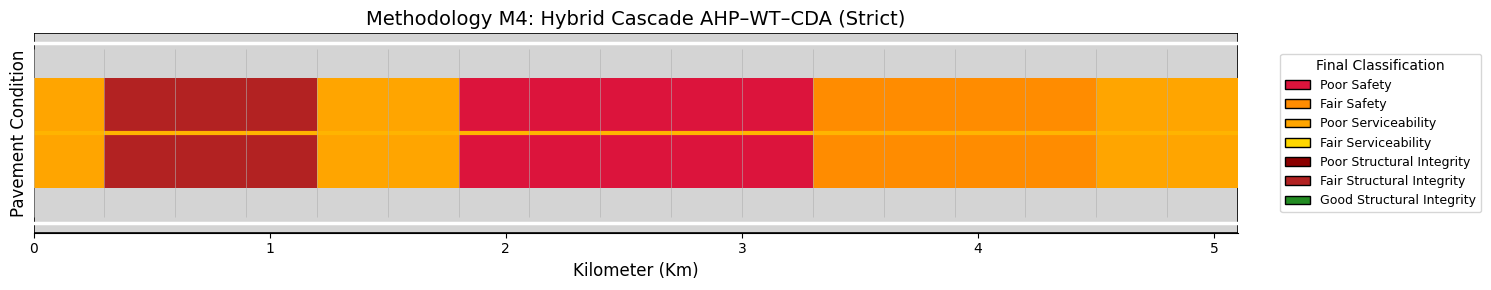

In [45]:
# o VUELTA
graficar_sentido_met4_estilo_autopista(
    secciones_fusionadas_vuelta,
    longitud_total_km,
    titulo="Methodology M4: Hybrid Cascade AHP–WT–CDA (Strict)"
)

###Tramos

In [46]:
import pandas as pd
import numpy as np

# ============================================================
# 1. FUNCIÓN PARA CONSTRUIR LA ETIQUETA FINAL
# ============================================================
def construir_etiqueta_final(df):
    df = df.copy()
    df["Etiqueta_Final"] = (
        df["Origen_Final"].astype(str).str.strip() + " " +
        df["Clasificacion_Final"].astype(str).str.strip()
    )
    return df


# ============================================================
# 2. FUNCIÓN PARA ETIQUETAR LOS SEGMENTOS BASE DE 300 m
# ============================================================
def etiquetar_segmentos_base(df_base, df_resultado):
    """
    df_base: DataFrame original con segmentos base (300 m)
             Debe tener KM_Inicio y KM_Fin

    df_resultado: salida de analizar_tramo_jerarquico_rigido_met4(...)
                  Debe tener KM_Inicio, KM_Fin, Origen_Final, Clasificacion_Final
    """
    df_base = df_base.copy()
    df_resultado = df_resultado.copy()

    # Asegurar etiqueta final en resultados
    df_resultado = construir_etiqueta_final(df_resultado)

    # Convertir km si aún están en formato estacado
    df_base["KM_Inicio"] = df_base["KM_Inicio"].apply(km_estacado_a_km)
    df_base["KM_Fin"]    = df_base["KM_Fin"].apply(km_estacado_a_km)

    # Inicializar columna
    df_base["Etiqueta_Final"] = "SIN_CLASIFICAR"

    # Asignar etiqueta del subtramo homogéneo que contiene al segmento base
    for i, row_base in df_base.iterrows():
        km_ini = float(row_base["KM_Inicio"])
        km_fin = float(row_base["KM_Fin"])

        match = df_resultado[
            (df_resultado["KM_Inicio"] <= km_ini + 1e-9) &
            (df_resultado["KM_Fin"]    >= km_fin - 1e-9)
        ]

        if not match.empty:
            df_base.at[i, "Etiqueta_Final"] = match.iloc[0]["Etiqueta_Final"]

    return df_base


# ============================================================
# 3. FUNCIÓN DE CONTEO EN EL ORDEN DE TU LEYENDA
# ============================================================
def contar_segmentos_por_clasificacion(df_etiquetado):
    orden = [
        "Seguridad Malo",
        "Seguridad Regular",
        "Operatividad Malo",
        "Operatividad Regular",
        "Integridad Estructural Malo",
        "Integridad Estructural Regular",
        "Integridad Estructural Bueno"
    ]

    conteo = (
        df_etiquetado["Etiqueta_Final"]
        .astype(str)
        .str.strip()
        .value_counts()
        .reindex(orden, fill_value=0)
    )

    return conteo


# ============================================================
# 4. EJECUCIÓN PARA IDA Y VUELTA
# ============================================================
# Etiquetar segmentos base de 300 m
base_ida_etiquetada = etiquetar_segmentos_base(df_tramo_ida, secciones_ida_m4)
base_vuelta_etiquetada = etiquetar_segmentos_base(df_tramo_vuelta, secciones_vuelta_m4)

# Conteos
conteo_ida = contar_segmentos_por_clasificacion(base_ida_etiquetada)
conteo_vuelta = contar_segmentos_por_clasificacion(base_vuelta_etiquetada)

# Total
base_total_etiquetada = pd.concat([base_ida_etiquetada, base_vuelta_etiquetada], ignore_index=True)
conteo_total = contar_segmentos_por_clasificacion(base_total_etiquetada)

# Imprimir resultados
print("="*60)
print("CONTEO DE SEGMENTOS BASE DE 300 m - METODOLOGÍA 4")
print("="*60)

print("\nIDA:")
print(conteo_ida)

print("\nVUELTA:")
print(conteo_vuelta)

print("\nTOTAL:")
print(conteo_total)


# ============================================================
# 5. VERIFICACIÓN DEL NÚMERO TOTAL DE SEGMENTOS BASE
# ============================================================
print("\n" + "="*60)
print("VERIFICACIÓN")
print("="*60)
print(f"Segmentos base IDA: {len(base_ida_etiquetada)}")
print(f"Suma conteo IDA:    {conteo_ida.sum()}")

print(f"\nSegmentos base VUELTA: {len(base_vuelta_etiquetada)}")
print(f"Suma conteo VUELTA:    {conteo_vuelta.sum()}")

print(f"\nSegmentos base TOTAL: {len(base_total_etiquetada)}")
print(f"Suma conteo TOTAL:    {conteo_total.sum()}")


# ============================================================
# 6. OPCIONAL: VER CADA SEGMENTO BASE CON SU ETIQUETA FINAL
# ============================================================
print("\n" + "="*60)
print("SEGMENTOS BASE IDA ETIQUETADOS")
print("="*60)
print(base_ida_etiquetada[["KM_Inicio", "KM_Fin", "Etiqueta_Final"]])

print("\n" + "="*60)
print("SEGMENTOS BASE VUELTA ETIQUETADOS")
print("="*60)
print(base_vuelta_etiquetada[["KM_Inicio", "KM_Fin", "Etiqueta_Final"]])

CONTEO DE SEGMENTOS BASE DE 300 m - METODOLOGÍA 4

IDA:
Etiqueta_Final
Seguridad Malo                    5
Seguridad Regular                 4
Operatividad Malo                 5
Operatividad Regular              0
Integridad Estructural Malo       0
Integridad Estructural Regular    3
Integridad Estructural Bueno      0
Name: count, dtype: int64

VUELTA:
Etiqueta_Final
Seguridad Malo                    5
Seguridad Regular                 4
Operatividad Malo                 5
Operatividad Regular              0
Integridad Estructural Malo       0
Integridad Estructural Regular    3
Integridad Estructural Bueno      0
Name: count, dtype: int64

TOTAL:
Etiqueta_Final
Seguridad Malo                    10
Seguridad Regular                  8
Operatividad Malo                 10
Operatividad Regular               0
Integridad Estructural Malo        0
Integridad Estructural Regular     6
Integridad Estructural Bueno       0
Name: count, dtype: int64

VERIFICACIÓN
Segmentos base IDA: 17
Suma

###Energías

In [47]:
columnas_segmentacion = [
    'KM_Inicio',
    'KM_Fin',

    'Factor_Etapa_1',
    'Energia_Segmentacion_Etapa_1',

    'Factor_Etapa_2',
    'Energia_Segmentacion_Etapa_2',

    'Factor_Etapa_3',
    'Energia_Segmentacion_Etapa_3',

    'Origen_Final',
    'Clasificacion_Final'
]

print(
    secciones_homogeneas_vuelta[
        columnas_segmentacion
    ].to_string(index=False)
)

 KM_Inicio  KM_Fin Factor_Etapa_1  Energia_Segmentacion_Etapa_1 Factor_Etapa_2  Energia_Segmentacion_Etapa_2 Factor_Etapa_3  Energia_Segmentacion_Etapa_3           Origen_Final Clasificacion_Final
       0.0     0.6             CF                      8.801053             JF                      2.000000            NaN                           NaN           Operatividad                Malo
       0.3     1.5             CF                      8.801053            IRI                      1.655834            DEF                      2.004465 Integridad Estructural             Regular
       0.3     1.5             CF                      8.801053            IRI                      1.655834            DEF                      2.004465 Integridad Estructural             Regular
       0.3     1.5             CF                      8.801053            IRI                      1.655834            DEF                      2.004465 Integridad Estructural             Regular
       1.2     

#Methodology M5: Hybrid Cascade AHP–WT–CDA (Tolerant)


   KM_Inicio  KM_Fin            Origen_Final Clasificacion_Final
0        0.0     0.6            Operatividad                Malo
1        0.3     1.5  Integridad Estructural             Regular
2        0.3     1.5  Integridad Estructural             Regular
3        0.3     1.5  Integridad Estructural             Regular
4        1.2     2.1            Operatividad                Malo
5        1.8     3.0               Seguridad                Malo
6        2.7     3.3               Seguridad                Malo
7        3.0     3.6               Seguridad                Malo
8        3.3     4.8               Seguridad             Regular
9        4.5     5.1            Operatividad                Malo
   KM_Inicio  KM_Fin            Origen_Final Clasificacion_Final
0        0.0     0.6            Operatividad                Malo
1        0.3     1.5  Integridad Estructural             Regular
2        0.3     1.5  Integridad Estructural             Regular
3        0.3     1.5  Int

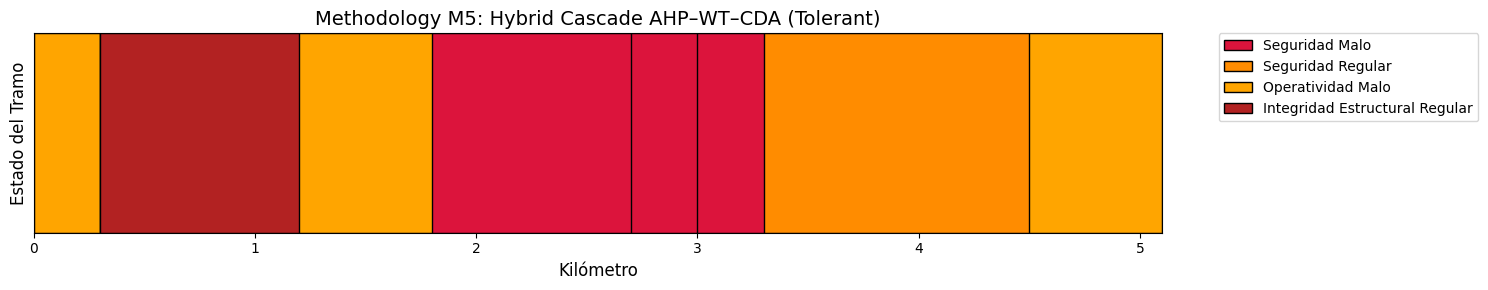

In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import pywt

# ============================================================
# METODOLOGÍA 4 (Wavelet + Diferencias Acumuladas) - ESTRICTA
# Seguridad (CF/TX) -> solo BUENO avanza
# Operatividad (IRI/JF) -> solo BUENO avanza
# Integridad (LTE/DEF) -> final
# ============================================================

# ==================== 3. FUNCIONES AUXILIARES ====================

def normalizar(valor, indicador, umbrales_dict=umbrales):
    """
    Normaliza a [0,1]:
      0 = condición buena / óptima
      1 = condición mala
    """
    if pd.isna(valor):
        return np.nan

    config = umbrales_dict.get(indicador)
    if not config:
        raise ValueError(f"Umbrales no definidos para: {indicador}")

    # Menor es mejor
    if indicador in ['IRI', 'JF', 'DEF']:
        X_min_bueno = config['Bueno'][0]
        X_limite_malo = config['Malo'][0]  # inicio de Malo
        if valor <= X_min_bueno:
            return 0.0
        if valor >= X_limite_malo:
            return 1.0
        if X_limite_malo == X_min_bueno:
            return 0.0
        return float((valor - X_min_bueno) / (X_limite_malo - X_min_bueno))

    # Mayor es mejor
    elif indicador in ['LTE', 'TX']:
        X_min_bueno = config['Bueno'][0]
        X_limite_malo = config['Malo'][1]  # tope superior de Malo
        if valor >= X_min_bueno:
            return 0.0
        if valor <= X_limite_malo:
            return 1.0
        if X_min_bueno == X_limite_malo:
            return 0.0
        return float((X_min_bueno - valor) / (X_min_bueno - X_limite_malo))

    # CF: óptimo intermedio (Bueno es un intervalo)
    elif indicador == 'CF':
        opt_min, opt_max = config['Bueno']          # (0.61, 0.90)
        malo_bajo_lim = config['Malo_Bajo'][1]      # 0.40
        malo_alto_lim = config['Malo_Alto'][0]      # 0.90

        # Óptimo
        if opt_min <= valor <= opt_max:
            return 0.0

        # Bajo (hacia Malo_Bajo)
        if valor < opt_min:
            den = (opt_min - malo_bajo_lim)
            if den == 0:
                return 1.0
            return float(np.clip((opt_min - valor) / den, 0.0, 1.0))

        # Alto (hacia Malo_Alto)
        den = (malo_alto_lim - opt_max)
        if den == 0:
            return 1.0
        return float(np.clip((valor - opt_max) / den, 0.0, 1.0))

    # Si llega aquí, no se definió: no penalizar
    return 0.0


def clasificar_valor(valor, indicador, umbrales_dict=umbrales):
    """
    Clasifica: 'Bueno', 'Regular' o 'Malo' según umbrales.
    Evita 'Desconocido' en CF por huecos (0.60–0.61).
    """
    if pd.isna(valor):
        return "N/A"

    u = umbrales_dict.get(indicador)
    if not u:
        return "Desconocido"

    # Menor es mejor
    if indicador in ['IRI', 'JF', 'DEF']:
        if valor <= u['Bueno'][1]:
            return 'Bueno'
        elif valor <= u['Regular'][1]:
            return 'Regular'
        else:
            return 'Malo'

    # Mayor es mejor
    elif indicador in ['LTE', 'TX']:
        if valor >= u['Bueno'][0]:
            return 'Bueno'
        elif valor >= u['Regular'][0]:
            return 'Regular'
        else:
            return 'Malo'

    # CF: óptimo intermedio (SIN HUECOS)
    elif indicador == 'CF':
        b0, b1 = u['Bueno']        # (0.61, 0.90)
        r0, r1 = u['Regular']      # (0.41, 0.60)
        mb1 = u['Malo_Bajo'][1]    # 0.40
        ma0 = u['Malo_Alto'][0]    # 0.90

        # Malo fuera del rango seguro (bajo o alto)
        if valor < mb1 or valor >= ma0:
            return 'Malo'

        # Bueno: rango óptimo
        if b0 <= valor < b1:
            return 'Bueno'

        # Regular: incluye el hueco (r1..b0)
        if r0 <= valor < b0:
            return 'Regular'

        # Respaldo por redondeos
        return 'Regular'

    return "Desconocido"


def calcular_energia_wavelet(serie_normalizada, wavelet_type='haar', wavelet_level=1):
    """
    Energía total de coeficientes wavelet usando Haar nivel 1.
    Adecuada para subtramos cortos.
    """
    s = pd.Series(serie_normalizada).astype(float)

    if s.isna().all():
        return 0.0

    s = s.interpolate(limit_direction="both").ffill().bfill()
    x = s.values

    w = pywt.Wavelet(wavelet_type)

    # Validación mínima según la longitud del filtro de la wavelet
    if len(x) < w.dec_len:
        return 0.0

    max_level = pywt.dwt_max_level(data_len=len(x), filter_len=w.dec_len)
    level = min(int(wavelet_level), int(max_level))

    if level <= 0:
        return 0.0

    coeffs = pywt.wavedec(x, wavelet_type, level=level)
    energia_total = sum(np.sum(np.square(c)) for c in coeffs)

    energia_total = float(energia_total)
    if abs(energia_total) < 1e-12:
        energia_total = 0.0

    return energia_total


def calcular_diferencias_acumuladas(data_series, k_factor=0.25):
    """
    Método CD/CUSUM-like para segmentación.
    - Interpola NaNs.
    - Detecta extremos locales del CD y filtra por salto mínimo k_factor.
    """
    if data_series is None or len(data_series) < 2:
        return []

    s = pd.Series(data_series).astype(float)
    if s.isna().all():
        return []

    s = s.interpolate(limit_direction="both").ffill().bfill()

    mean_val = s.mean()
    std_dev = s.std(ddof=0)

    if std_dev == 0 or np.isnan(std_dev):
        return [{
            'start_idx': s.index[0],
            'end_idx': s.index[-1],
            'mean_value': float(mean_val)
        }]

    z = (s - mean_val) / std_dev
    cd = z.cumsum()

    d1 = cd.diff()
    sign = np.sign(d1).replace(0, np.nan).ffill().bfill()
    extremos = cd.index[(sign.shift(-1) != sign) & (sign.notna())]

    change_points = [cd.index[0]]
    last_cp = change_points[-1]

    for idx in extremos:
        if idx == last_cp:
            continue
        if abs(cd.loc[idx] - cd.loc[last_cp]) >= k_factor:
            change_points.append(idx)
            last_cp = idx

    if cd.index[-1] not in change_points:
        change_points.append(cd.index[-1])

    change_points = sorted(set(change_points))

    homogeneous_sections = []
    for i in range(len(change_points) - 1):
        start_index = change_points[i]
        end_index = change_points[i + 1]
        section_data = s.loc[start_index:end_index]
        if not section_data.empty:
            homogeneous_sections.append({
                'start_idx': start_index,
                'end_idx': end_index,
                'mean_value': float(section_data.mean())
            })

    return homogeneous_sections


# ==================== 4. FUNCIÓN PRINCIPAL METODOLOGÍA 4 ====================

def analizar_tramo_jerarquico_rigido_met4(df, umbrales, k_factor_cd=0.25, wavelet_level=1):
    """
    METODOLOGÍA 4 (estricta):
      1) Seguridad: CF vs TX
      2) Operatividad: IRI vs JF
      3) Integridad estructural: LTE vs DEF

    - En cada nivel: se elige el factor con mayor energía wavelet.
    - Segmentación con CD.
    - SOLO BUENOS avanzan al siguiente nivel.
    """
    df_result = df.copy()

    df_result["KM_Inicio"] = df_result["KM_Inicio"].apply(km_estacado_a_km)
    df_result["KM_Fin"]    = df_result["KM_Fin"].apply(km_estacado_a_km)

    # Normalizar todos los indicadores
    for col in ['IRI', 'JF', 'LTE', 'DEF', 'CF', 'TX']:
        df_result[f'{col}_Normalizado'] = df_result[col].apply(lambda x: normalizar(x, col, umbrales))

    sections_to_process = [{
        'start_idx': df_result.index[0],
        'end_idx': df_result.index[-1],
        'prev_info': {}
    }]

    final_homogeneous_sections = []

    # ---------- ETAPA 1: SEGURIDAD (CF vs TX) ----------
    next_stage_sections = []

    for section in sections_to_process:
        subset_df = df_result.loc[section['start_idx']:section['end_idx']]
        if subset_df.empty:
            continue

        cf_norm = subset_df['CF_Normalizado']
        tx_norm = subset_df['TX_Normalizado']

        energia_cf = calcular_energia_wavelet(cf_norm, wavelet_type='haar', wavelet_level=wavelet_level)
        energia_tx = calcular_energia_wavelet(tx_norm, wavelet_type='haar', wavelet_level=wavelet_level)

        if energia_cf >= energia_tx:
            critical_factor = 'CF'
            series_for_cd = cf_norm
        else:
            critical_factor = 'TX'
            series_for_cd = tx_norm

        cd_sections = calcular_diferencias_acumuladas(series_for_cd, k_factor=k_factor_cd)
        if not cd_sections:
            cd_sections = [{
                'start_idx': section['start_idx'],
                'end_idx': section['end_idx'],
                'mean_value': float(pd.Series(series_for_cd).astype(float).mean())
            }]

        for cd_sec in cd_sections:
            sec_start_idx = cd_sec['start_idx']
            sec_end_idx = cd_sec['end_idx']

            mean_original_value = float(df_result.loc[sec_start_idx:sec_end_idx, critical_factor].mean())
            status = clasificar_valor(mean_original_value, critical_factor, umbrales)

            section_info = {
                'KM_Inicio_Idx': sec_start_idx,
                'KM_Fin_Idx': sec_end_idx,
                'KM_Inicio': float(df_result.loc[sec_start_idx, 'KM_Inicio']),
                'KM_Fin': float(df_result.loc[sec_end_idx, 'KM_Fin']),
                'Factor_Etapa_1': critical_factor,
                'Valor_Original_Etapa_1': mean_original_value,
                'Valor_Normalizado_Etapa_1': float(cd_sec['mean_value']),
                'Clasificacion_Etapa_1': status,
                'Critico_Etapa_1': critical_factor
            }

            if status == 'Bueno':
                next_stage_sections.append({
                    'start_idx': sec_start_idx,
                    'end_idx': sec_end_idx,
                    'prev_info': section_info
                })
            else:
                section_info['Origen_Final'] = 'Seguridad'
                section_info['Clasificacion_Final'] = status
                section_info['Motivo_Clasificacion_Final'] = f"Detenido en Etapa 1 (Seguridad: {critical_factor}, {status})"
                final_homogeneous_sections.append(section_info)

    sections_to_process = next_stage_sections
    next_stage_sections = []

    # ---------- ETAPA 2: OPERATIVIDAD (IRI vs JF) ----------
    for section in sections_to_process:
        subset_df = df_result.loc[section['start_idx']:section['end_idx']]
        if subset_df.empty:
            info = section['prev_info']
            info['Origen_Final'] = 'Operatividad'
            info['Clasificacion_Final'] = 'N/A'
            info['Motivo_Clasificacion_Final'] = "Detenido en Etapa 2 (sin datos)"
            final_homogeneous_sections.append(info)
            continue

        iri_norm = subset_df['IRI_Normalizado']
        jf_norm = subset_df['JF_Normalizado']

        energia_iri = calcular_energia_wavelet(iri_norm, wavelet_type='haar', wavelet_level=wavelet_level)
        energia_jf = calcular_energia_wavelet(jf_norm, wavelet_type='haar', wavelet_level=wavelet_level)

        if energia_iri >= energia_jf:
            critical_factor = 'IRI'
            series_for_cd = iri_norm
        else:
            critical_factor = 'JF'
            series_for_cd = jf_norm

        cd_sections = calcular_diferencias_acumuladas(series_for_cd, k_factor=k_factor_cd)
        if not cd_sections:
            cd_sections = [{
                'start_idx': section['start_idx'],
                'end_idx': section['end_idx'],
                'mean_value': float(pd.Series(series_for_cd).astype(float).mean())
            }]

        for cd_sec in cd_sections:
            sec_start_idx = cd_sec['start_idx']
            sec_end_idx = cd_sec['end_idx']

            mean_original_value = float(df_result.loc[sec_start_idx:sec_end_idx, critical_factor].mean())
            status = clasificar_valor(mean_original_value, critical_factor, umbrales)

            current_section_info = section['prev_info'].copy()
            current_section_info.update({
                'Factor_Etapa_2': critical_factor,
                'Valor_Original_Etapa_2': mean_original_value,
                'Valor_Normalizado_Etapa_2': float(cd_sec['mean_value']),
                'Clasificacion_Etapa_2': status,
                'Critico_Etapa_2': critical_factor
            })

            if status == 'Bueno':
                next_stage_sections.append({
                    'start_idx': sec_start_idx,
                    'end_idx': sec_end_idx,
                    'prev_info': current_section_info
                })
            else:
                current_section_info['Origen_Final'] = 'Operatividad'
                current_section_info['Clasificacion_Final'] = status
                current_section_info['Motivo_Clasificacion_Final'] = f"Detenido en Etapa 2 (Operatividad: {critical_factor}, {status})"
                final_homogeneous_sections.append(current_section_info)

    sections_to_process = next_stage_sections

    # ---------- ETAPA 3: INTEGRIDAD ESTRUCTURAL (LTE vs DEF) ----------
    for section in sections_to_process:
        subset_df = df_result.loc[section['start_idx']:section['end_idx']]
        if subset_df.empty:
            info = section['prev_info']
            info['Origen_Final'] = 'Integridad Estructural'
            info['Clasificacion_Final'] = 'N/A'
            info['Motivo_Clasificacion_Final'] = "Detenido en Etapa 3 (sin datos)"
            final_homogeneous_sections.append(info)
            continue

        lte_norm = subset_df['LTE_Normalizado']
        def_norm = subset_df['DEF_Normalizado']

        energia_lte = calcular_energia_wavelet(lte_norm, wavelet_type='haar', wavelet_level=wavelet_level)
        energia_def = calcular_energia_wavelet(def_norm, wavelet_type='haar', wavelet_level=wavelet_level)

        if energia_lte >= energia_def:
            critical_factor = 'LTE'
            series_for_cd = lte_norm
        else:
            critical_factor = 'DEF'
            series_for_cd = def_norm

        cd_sections = calcular_diferencias_acumuladas(series_for_cd, k_factor=k_factor_cd)
        if not cd_sections:
            cd_sections = [{
                'start_idx': section['start_idx'],
                'end_idx': section['end_idx'],
                'mean_value': float(pd.Series(series_for_cd).astype(float).mean())
            }]

        for cd_sec in cd_sections:
            sec_start_idx = cd_sec['start_idx']
            sec_end_idx = cd_sec['end_idx']

            mean_original_value = float(df_result.loc[sec_start_idx:sec_end_idx, critical_factor].mean())
            status = clasificar_valor(mean_original_value, critical_factor, umbrales)

            current_section_info = section['prev_info'].copy()
            current_section_info.update({
                'Factor_Etapa_3': critical_factor,
                'Valor_Original_Etapa_3': mean_original_value,
                'Valor_Normalizado_Etapa_3': float(cd_sec['mean_value']),
                'Clasificacion_Etapa_3': status,
                'Critico_Etapa_3': critical_factor
            })

            current_section_info['Origen_Final'] = 'Integridad Estructural'
            current_section_info['Clasificacion_Final'] = status
            current_section_info['Motivo_Clasificacion_Final'] = f"Finalizada en Etapa 3 (Integridad: {critical_factor}, {status})"
            final_homogeneous_sections.append(current_section_info)

    df_final_sections = pd.DataFrame(final_homogeneous_sections).sort_values(by='KM_Inicio').reset_index(drop=True)

    # Garantizar columnas de etapa
    for i in range(1, 4):
        for base in [
            'Clasificacion_Etapa_', 'Critico_Etapa_', 'Factor_Etapa_',
            'Valor_Original_Etapa_', 'Valor_Normalizado_Etapa_'
        ]:
            col = f"{base}{i}"
            if col not in df_final_sections.columns:
                df_final_sections[col] = np.nan

    return df_final_sections


# ==================== 6. VISUALIZACIÓN SUMARIA ====================

def plot_homogeneous_sections_summary_met4(df_sections, longitud_total_km, titulo=None):
    fig, ax = plt.subplots(figsize=(15, 3))

    color_map = {
        "Seguridad Malo":                 '#DC143C',
        "Seguridad Regular":              '#FF8C00',
        "Operatividad Malo":              '#FFA500',
        "Operatividad Regular":           '#FFD700',
        "Integridad Estructural Malo":    '#8B0000',
        "Integridad Estructural Regular": '#B22222',
        "Integridad Estructural Bueno":   '#228B22',
        # opcional por si sale:
        "Seguridad N/A":                  '#A9A9A9',
        "Operatividad N/A":               '#A9A9A9',
        "Integridad Estructural N/A":     '#A9A9A9',
        "Seguridad Desconocido":          '#A9A9A9',
        "Operatividad Desconocido":       '#A9A9A9',
        "Integridad Estructural Desconocido": '#A9A9A9',
    }

    for _, row in df_sections.iterrows():
        start_km = float(row['KM_Inicio'])
        end_km = float(row['KM_Fin'])

        origen = str(row.get('Origen_Final', 'Desconocido')).strip()
        clasif = str(row.get('Clasificacion_Final', 'Desconocido')).strip()
        label = f"{origen} {clasif}"
        color = color_map.get(label, '#A9A9A9')

        rect = mpatches.Rectangle(
            (start_km, 0),
            end_km - start_km,
            1,
            facecolor=color,
            edgecolor='black',
            linewidth=1
        )
        ax.add_patch(rect)

    ax.set_xlim(0, float(df_sections['KM_Fin'].max()))
    ax.set_ylim(0, 1)
    ax.set_yticks([])
    ax.set_xlabel('Kilómetro', fontsize=12)
    ax.set_ylabel('Estado del Tramo', fontsize=12)

    if titulo is None:
        titulo = 'METODOLOGÍA 5: Segmentación Jerárquica Amplia –AHP-WT.'
    ax.set_title(titulo, fontsize=14)

    ax.grid(False)
    plt.xticks(np.arange(0, longitud_total_km + 1, 1.0))

    # Leyenda en el orden que pediste
    orden_leyenda = [
        "Seguridad Malo",
        "Seguridad Regular",
        "Operatividad Malo",
        "Operatividad Regular",
        "Integridad Estructural Malo",
        "Integridad Estructural Regular",
        "Integridad Estructural Bueno"
    ]

    labels_presentes = {
        f"{str(r.get('Origen_Final','')).strip()} {str(r.get('Clasificacion_Final','')).strip()}"
        for _, r in df_sections.iterrows()
    }

    handles = [
        mpatches.Patch(facecolor=color_map[lbl], edgecolor='black', label=lbl)
        for lbl in orden_leyenda
        if lbl in labels_presentes
    ]

    if handles:
        ax.legend(handles=handles, bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)

    plt.tight_layout()
    plt.show()


# ==================== 7. EJECUCIÓN ====================

secciones_homogeneas_ida = analizar_tramo_jerarquico_rigido_met4(df_tramo_ida, umbrales, k_factor_cd=0.25, wavelet_level=1)
print(secciones_homogeneas_ida[['KM_Inicio','KM_Fin','Origen_Final','Clasificacion_Final']])

secciones_homogeneas_vuelta = analizar_tramo_jerarquico_rigido_met4(df_tramo_vuelta, umbrales, k_factor_cd=0.25, wavelet_level=1)
print(secciones_homogeneas_vuelta[['KM_Inicio','KM_Fin','Origen_Final','Clasificacion_Final']])

plot_homogeneous_sections_summary_met4(
    secciones_homogeneas_ida,
    longitud_total_km=longitud_total_km,
    titulo="Methodology M5: Hybrid Cascade AHP–WT–CDA (Tolerant)"
)

In [49]:
def analizar_tramo_jerarquico_rigido_met5(df, umbrales, k_factor_cd=0.25, wavelet_level=1):
    """
    METODOLOGÍA 5 (flexible):
      1) Seguridad: CF vs TX
      2) Operatividad: IRI vs JF
      3) Integridad estructural: LTE vs DEF

    - En cada nivel: se elige el factor con mayor energía wavelet.
    - Segmentación con CD.
    - AVANZAN: Bueno y Regular
    - SE DETIENEN: Malo
    """
    df_result = df.copy()

    df_result["KM_Inicio"] = df_result["KM_Inicio"].apply(km_estacado_a_km)
    df_result["KM_Fin"]    = df_result["KM_Fin"].apply(km_estacado_a_km)


    # Normalizar todos los indicadores
    for col in ['IRI', 'JF', 'LTE', 'DEF', 'CF', 'TX']:
        df_result[f'{col}_Normalizado'] = df_result[col].apply(
            lambda x: normalizar(x, col, umbrales)
        )

    sections_to_process = [{
        'start_idx': df_result.index[0],
        'end_idx': df_result.index[-1],
        'prev_info': {}
    }]
    final_homogeneous_sections = []

    # ===================== ETAPA 1: SEGURIDAD (CF vs TX) =====================
    next_stage_sections = []

    for section in sections_to_process:
        subset_df = df_result.loc[section['start_idx']:section['end_idx']]
        if subset_df.empty:
            continue

        cf_norm = subset_df['CF_Normalizado']
        tx_norm = subset_df['TX_Normalizado']
        min_len = 2**wavelet_level

        energia_cf = calcular_energia_wavelet(cf_norm, wavelet_level=wavelet_level) if len(cf_norm) >= min_len else 0.0
        energia_tx = calcular_energia_wavelet(tx_norm, wavelet_level=wavelet_level) if len(tx_norm) >= min_len else 0.0
        #
        if energia_cf >= energia_tx:
            critical_factor = 'CF'
            energia_segmentacion = energia_cf
            series_for_cd = cf_norm
        else:
            critical_factor = 'TX'
            energia_segmentacion = energia_tx
            series_for_cd = tx_norm

        # Si ambas energías son cero, se conserva CF como criterio de desempate
        if energia_cf == 0 and energia_tx == 0:
            critical_factor = 'CF'
            energia_segmentacion = energia_cf
            series_for_cd = cf_norm

        cd_sections = calcular_diferencias_acumuladas(series_for_cd, k_factor=k_factor_cd)
        if not cd_sections:
            cd_sections = [{
                'start_idx': section['start_idx'],
                'end_idx': section['end_idx'],
                'mean_value': series_for_cd.mean()
            }]

        for cd_sec in cd_sections:
            sec_start_idx = cd_sec['start_idx']
            sec_end_idx = cd_sec['end_idx']

            mean_original_value = df_result.loc[sec_start_idx:sec_end_idx, critical_factor].mean()
            status = clasificar_valor(mean_original_value, critical_factor, umbrales)

            section_info = {
                'KM_Inicio_Idx': sec_start_idx,
                'KM_Fin_Idx': sec_end_idx,
                'KM_Inicio': df_result.loc[sec_start_idx, 'KM_Inicio'],
                'KM_Fin': df_result.loc[sec_end_idx, 'KM_Fin'],
                'Factor_Etapa_1': critical_factor,
                'Valor_Original_Etapa_1': mean_original_value,
                'Valor_Normalizado_Etapa_1': cd_sec['mean_value'],
                'Clasificacion_Etapa_1': status,
                'Critico_Etapa_1': critical_factor,
                'Energia_Segmentacion_Etapa_1': energia_segmentacion
            }

            # ✅ MET 5: avanzan Bueno y Regular
            if status in ('Bueno', 'Regular'):
                next_stage_sections.append({
                    'start_idx': sec_start_idx,
                    'end_idx': sec_end_idx,
                    'prev_info': section_info
                })
            else:
                section_info['Origen_Final'] = 'Seguridad'
                section_info['Clasificacion_Final'] = status
                section_info['Motivo_Clasificacion_Final'] = f"Detenido en Etapa 1 (Seguridad: {critical_factor}, {status})"
                final_homogeneous_sections.append(section_info)

    sections_to_process = next_stage_sections
    next_stage_sections = []

    # ===================== ETAPA 2: OPERATIVIDAD (IRI vs JF) =====================
    for section in sections_to_process:
        subset_df = df_result.loc[section['start_idx']:section['end_idx']]
        if subset_df.empty:
            section['prev_info']['Origen_Final'] = 'Operatividad'
            section['prev_info']['Clasificacion_Final'] = 'N/A'
            section['prev_info']['Motivo_Clasificacion_Final'] = "Detenido en Etapa 2 (sin datos)"
            final_homogeneous_sections.append(section['prev_info'])
            continue

        iri_norm = subset_df['IRI_Normalizado']
        jf_norm = subset_df['JF_Normalizado']
        min_len = 2**wavelet_level

        energia_iri = calcular_energia_wavelet(iri_norm, wavelet_level=wavelet_level) if len(iri_norm) >= min_len else 0.0
        energia_jf = calcular_energia_wavelet(jf_norm, wavelet_level=wavelet_level) if len(jf_norm) >= min_len else 0.0
        #
        if energia_iri >= energia_jf:
            critical_factor = 'IRI'
            energia_segmentacion = energia_iri
            series_for_cd = iri_norm
        else:
            critical_factor = 'JF'
            energia_segmentacion = energia_jf
            series_for_cd = jf_norm

        # Si ambas energías son cero, se conserva IRI como criterio de desempate
        if energia_iri == 0 and energia_jf == 0:
            critical_factor = 'IRI'
            energia_segmentacion = energia_iri
            series_for_cd = iri_norm

        cd_sections = calcular_diferencias_acumuladas(series_for_cd, k_factor=k_factor_cd)
        if not cd_sections:
            cd_sections = [{
                'start_idx': section['start_idx'],
                'end_idx': section['end_idx'],
                'mean_value': series_for_cd.mean()
            }]

        for cd_sec in cd_sections:
            sec_start_idx = cd_sec['start_idx']
            sec_end_idx = cd_sec['end_idx']

            mean_original_value = df_result.loc[sec_start_idx:sec_end_idx, critical_factor].mean()
            status = clasificar_valor(mean_original_value, critical_factor, umbrales)

            current_section_info = section['prev_info'].copy()
            current_section_info.update({
                'Factor_Etapa_2': critical_factor,
                'Valor_Original_Etapa_2': mean_original_value,
                'Valor_Normalizado_Etapa_2': cd_sec['mean_value'],
                'Clasificacion_Etapa_2': status,
                'Critico_Etapa_2': critical_factor,
                'Energia_Segmentacion_Etapa_2': energia_segmentacion
            })

            # ✅ MET 5: avanzan Bueno y Regular
            if status in ('Bueno', 'Regular'):
                next_stage_sections.append({
                    'start_idx': sec_start_idx,
                    'end_idx': sec_end_idx,
                    'prev_info': current_section_info
                })
            else:
                current_section_info['Origen_Final'] = 'Operatividad'
                current_section_info['Clasificacion_Final'] = status
                current_section_info['Motivo_Clasificacion_Final'] = f"Detenido en Etapa 2 (Operatividad: {critical_factor}, {status})"
                final_homogeneous_sections.append(current_section_info)

    sections_to_process = next_stage_sections
    next_stage_sections = []

    # ===================== ETAPA 3: INTEGRIDAD (LTE vs DEF) =====================
    for section in sections_to_process:
        subset_df = df_result.loc[section['start_idx']:section['end_idx']]
        if subset_df.empty:
            section['prev_info']['Origen_Final'] = 'Integridad Estructural'
            section['prev_info']['Clasificacion_Final'] = 'N/A'
            section['prev_info']['Motivo_Clasificacion_Final'] = "Detenido en Etapa 3 (sin datos)"
            final_homogeneous_sections.append(section['prev_info'])
            continue

        lte_norm = subset_df['LTE_Normalizado']
        def_norm = subset_df['DEF_Normalizado']
        min_len = 2**wavelet_level

        energia_lte = calcular_energia_wavelet(lte_norm, wavelet_level=wavelet_level) if len(lte_norm) >= min_len else 0.0
        energia_def = calcular_energia_wavelet(def_norm, wavelet_level=wavelet_level) if len(def_norm) >= min_len else 0.0
        #
        if energia_lte >= energia_def:
            critical_factor = 'LTE'
            energia_segmentacion = energia_lte
            series_for_cd = lte_norm
        else:
            critical_factor = 'DEF'
            energia_segmentacion = energia_def
            series_for_cd = def_norm

        # Si ambas energías son cero, se conserva LTE como criterio de desempate
        if energia_lte == 0 and energia_def == 0:
            critical_factor = 'DEF'
            energia_segmentacion = energia_def
            series_for_cd = def_norm

        cd_sections = calcular_diferencias_acumuladas(series_for_cd, k_factor=k_factor_cd)
        if not cd_sections:
            cd_sections = [{
                'start_idx': section['start_idx'],
                'end_idx': section['end_idx'],
                'mean_value': series_for_cd.mean()
            }]

        for cd_sec in cd_sections:
            sec_start_idx = cd_sec['start_idx']
            sec_end_idx = cd_sec['end_idx']

            mean_original_value = df_result.loc[sec_start_idx:sec_end_idx, critical_factor].mean()
            status = clasificar_valor(mean_original_value, critical_factor, umbrales)

            current_section_info = section['prev_info'].copy()
            current_section_info.update({
                'Factor_Etapa_3': critical_factor,
                'Valor_Original_Etapa_3': mean_original_value,
                'Valor_Normalizado_Etapa_3': cd_sec['mean_value'],
                'Clasificacion_Etapa_3': status,
                'Critico_Etapa_3': critical_factor,
                'Energia_Segmentacion_Etapa_3': energia_segmentacion
            })

            # En etapa 3 ya es final
            current_section_info['Origen_Final'] = 'Integridad Estructural'
            current_section_info['Clasificacion_Final'] = status
            current_section_info['Motivo_Clasificacion_Final'] = f"Finalizada en Etapa 3 (Integridad: {critical_factor}, {status})"
            final_homogeneous_sections.append(current_section_info)

    df_final_sections = pd.DataFrame(final_homogeneous_sections)
    df_final_sections = df_final_sections.sort_values(by='KM_Inicio').reset_index(drop=True)

    # Garantizar columnas de etapa
    #
    for i in range(1, 4):
        for base in [
            'Clasificacion_Etapa_',
            'Critico_Etapa_',
            'Factor_Etapa_',
            'Energia_Segmentacion_Etapa_',
            'Valor_Original_Etapa_',
            'Valor_Normalizado_Etapa_'
        ]:
            col = f"{base}{i}"

            if col not in df_final_sections.columns:
                df_final_sections[col] = np.nan

        return df_final_sections


In [50]:
secciones_met5_ida = analizar_tramo_jerarquico_rigido_met5(df_tramo_ida, umbrales, k_factor_cd=0.25, wavelet_level=1)
secciones_met5_vuelta = analizar_tramo_jerarquico_rigido_met5(df_tramo_vuelta, umbrales, k_factor_cd=0.25, wavelet_level=1)


In [51]:
def fusionar_secciones_robusto(df_sections, tol=1e-6):
    df = df_sections.copy()

    # Label_Final = "Origen_Final Clasificacion_Final"
    if "Label_Final" not in df.columns:
        df["Label_Final"] = (
            df["Origen_Final"].astype(str).str.strip() + " " +
            df["Clasificacion_Final"].astype(str).str.strip()
        )

    df = df.sort_values("KM_Inicio").reset_index(drop=True)

    out = []
    current = df.iloc[0].to_dict()

    for i in range(1, len(df)):
        row = df.iloc[i]
        mismo_label = (row["Label_Final"] == current["Label_Final"])

        # contiguo (o traslape leve)
        contiguo = (abs(row["KM_Inicio"] - current["KM_Fin"]) <= tol) or (row["KM_Inicio"] <= current["KM_Fin"] + tol)

        if mismo_label and contiguo:
            # extender
            current["KM_Fin"] = max(current["KM_Fin"], row["KM_Fin"])
            # (opcional) puedes promediar valores originales/normalizados si quieres, pero no es necesario para la gráfica
        else:
            out.append(current)
            current = row.to_dict()

    out.append(current)
    return pd.DataFrame(out)


In [52]:
secciones_fusionadas_met5_ida = fusionar_secciones_robusto(secciones_met5_ida)
secciones_fusionadas_met5_vuelta = fusionar_secciones_robusto(secciones_met5_vuelta)

##Larguillo

###Carretera

In [53]:
def graficar_sentido_met5_formato_autopista(df_secciones_fusionadas, longitud_total_km,
                                          titulo="Methodology M5: Hybrid Cascade AHP–WT–CDA (Tolerant)"):
    import matplotlib.colors as mcolors
    import matplotlib.pyplot as plt
    import matplotlib.patches as mpatches
    import numpy as np

    # 1. TRADUCCIÓN DEL COLOR_MAP (Claves en inglés)
    color_map = {
        "Poor Safety":                  '#DC143C',
        "Fair Safety":                  '#FF8C00',
        "Poor Serviceability":          '#FFA500',
        "Fair Serviceability":          '#FFD700',
        "Poor Structural Integrity":    '#8B0000',
        "Fair Structural Integrity":    '#B22222',
        "Good Structural Integrity":    '#228B22'
    }

    df_plot = df_secciones_fusionadas.copy()

    # 2. TRADUCCIÓN AUTOMÁTICA DE LOS DATOS (
    df_plot["Label_Final"] = (
        df_plot["Origen_Final"].astype(str).str.strip() + " " +
        df_plot["Clasificacion_Final"].astype(str).str.strip()
    )

    # Aplicamos el reemplazo para que coincida con el color_map en inglés
    traduccion_dict = {
        "Seguridad Malo": "Poor Safety",
        "Seguridad Regular": "Fair Safety",
        "Operatividad Malo": "Poor Serviceability",
        "Operatividad Regular": "Fair Serviceability",
        "Integridad Estructural Malo": "Poor Structural Integrity",
        "Integridad Estructural Regular": "Fair Structural Integrity",
        "Integridad Estructural Bueno": "Good Structural Integrity"
    }
    df_plot["Label_Final"] = df_plot["Label_Final"].replace(traduccion_dict)

    max_km = float(max(df_ida["KM_Fin"].max(), df_vuelta["KM_Fin"].max()))

    plt.figure(figsize=(15, 3))
    ax = plt.gca()
    road_height = 1.0

    # Fondo concreto
    carretera = mpatches.Rectangle((0, 0), max_km, road_height,
                                    facecolor="#D4D4D4", edgecolor='black', linewidth=1.2)
    ax.add_patch(carretera)

    # Líneas blancas y amarilla continua
    ax.plot([0, max_km], [0.95, 0.95], color='white', linewidth=2.5)
    ax.plot([0, max_km], [0.05, 0.05], color='white', linewidth=2.5)
    ax.plot([0, max_km], [0.50, 0.50], color='#FFB400', linewidth=3.0)

    # Juntas de losas
    longitud_losa_m = 300
    longitud_losa_km = longitud_losa_m / 1000.0
    x = 0.0
    while x <= max_km + longitud_losa_km:
        ax.vlines(x, 0.08, 0.92, colors='#B0B0B0', linewidth=0.4)
        x += longitud_losa_km

    # Banda de color (Usando el label ya traducido)
    band_height = 0.55
    band_y = (road_height - band_height) / 2

    for _, row in df_plot.iterrows():
        start_km = float(row["KM_Inicio"])
        end_km   = float(row["KM_Fin"])
        label    = str(row["Label_Final"]).strip()

        color_base = color_map.get(label, "#AAAAAA") # Ahora sí encontrará el color
        r, g, b = mcolors.to_rgb(color_base)

        rect = mpatches.Rectangle(
            (start_km, band_y),
            max(0.0, end_km - start_km),
            band_height,
            facecolor=(r, g, b, 1.0),
            edgecolor='none'
        )
        ax.add_patch(rect)

    # Configuración de ejes
    ax.set_xlim(0, max_km)
    ax.set_ylim(0, road_height)
    ax.set_yticks([])
    ax.set_xlabel("Kilometer (Km)", fontsize=12)
    ax.set_ylabel("Pavement Condition", fontsize=12)
    plt.xticks(np.arange(0, max_km, 1.0), fontsize=10)

    ax.set_title(titulo, fontsize=14)

    # 3. TRADUCCIÓN DE LA LEYENDA
    orden_leyenda = [
        "Poor Safety",
        "Fair Safety",
        "Poor Serviceability",
        "Fair Serviceability",
        "Poor Structural Integrity",
        "Fair Structural Integrity",
        "Good Structural Integrity",
    ]

    handles = [
        mpatches.Patch(
            facecolor=color_map.get(lbl, "#AAAAAA"), # Cambiado de colores_met4 a color_map
            edgecolor="black",
            label=lbl
        )
        for lbl in orden_leyenda
    ]

    ax.legend(
        handles=handles,
        loc="center left",
        bbox_to_anchor=(1.03, 0.5),
        fontsize=9,
        title="Final Classification" # Corregido spelling
    )

    plt.tight_layout()
    plt.savefig("MET-5.png", dpi=300, bbox_inches="tight")
    plt.show()

Ida

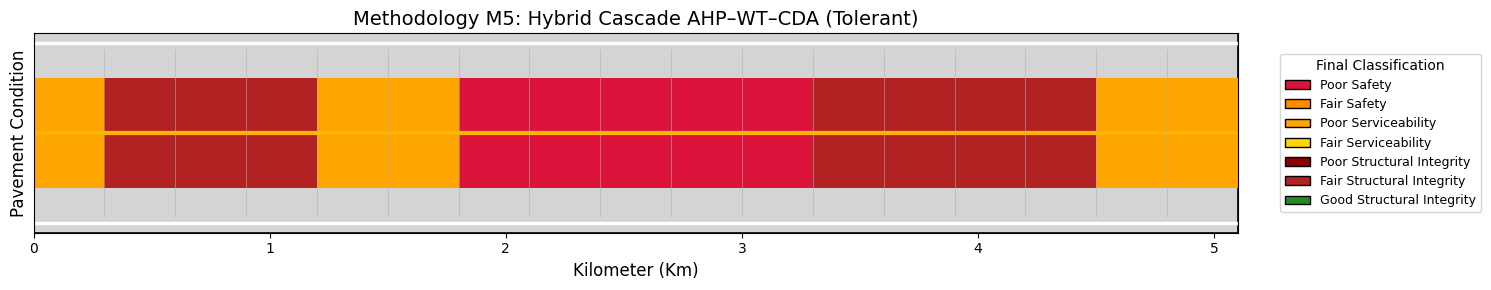

In [54]:
graficar_sentido_met5_formato_autopista(secciones_fusionadas_met5_ida, longitud_total_km,
                                        titulo="Methodology M5: Hybrid Cascade AHP–WT–CDA (Tolerant)")


Vuelta

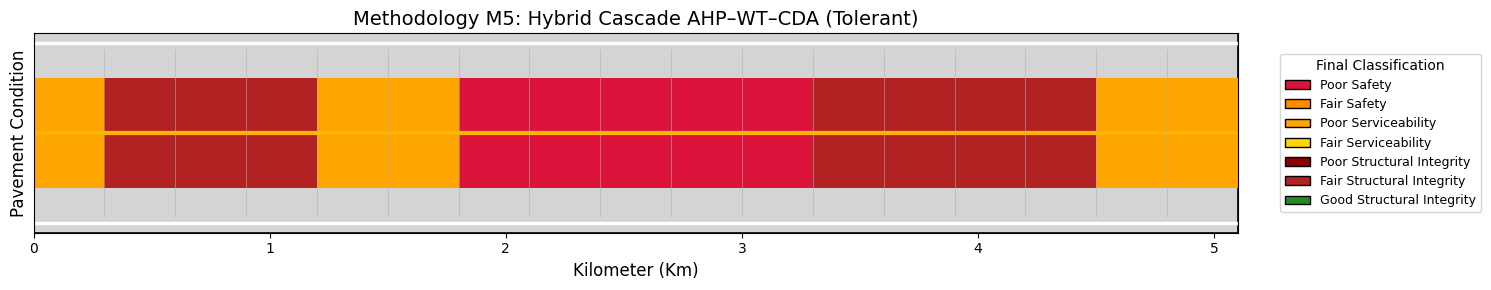

In [55]:
graficar_sentido_met5_formato_autopista(secciones_fusionadas_met5_vuelta, longitud_total_km,
                                        titulo="Methodology M5: Hybrid Cascade AHP–WT–CDA (Tolerant)")


###Autopista

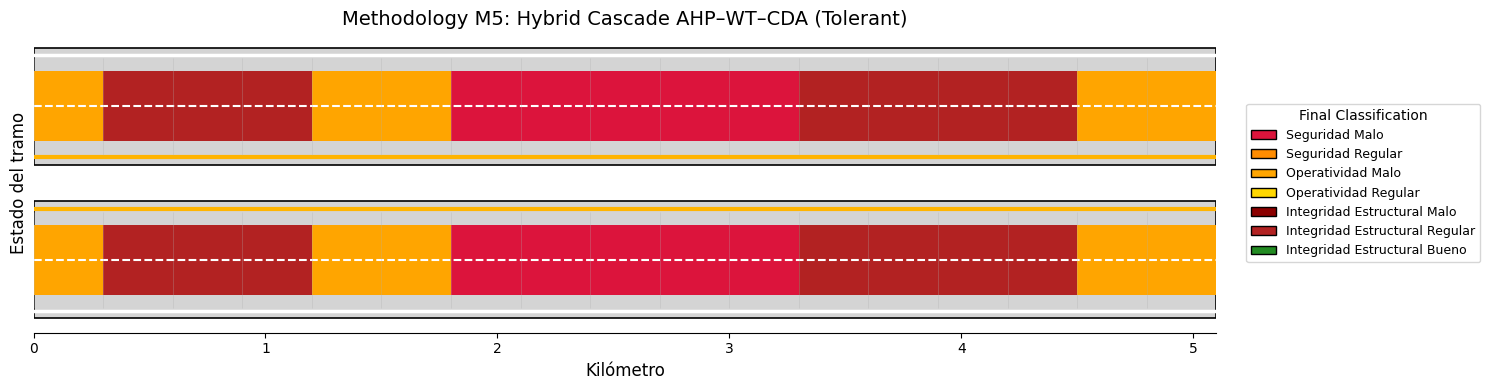

In [56]:
graficar_autopista_met4(
    secciones_fusionadas_met5_ida,
    secciones_fusionadas_met5_vuelta,
    longitud_total_km,
    titulo="Methodology M5: Hybrid Cascade AHP–WT–CDA (Tolerant)"
)


###Tramos

In [57]:
def contar_m5(df):
    etiquetas = (
        df['Origen_Final'].astype(str).str.strip() + ' ' +
        df['Clasificacion_Final'].astype(str).str.strip()
    )

    orden = [
        'Seguridad Malo',
        'Seguridad Regular',
        'Operatividad Malo',
        'Operatividad Regular',
        'Integridad Estructural Malo',
        'Integridad Estructural Regular',
        'Integridad Estructural Bueno'
    ]

    return etiquetas.value_counts().reindex(orden, fill_value=0)

print(contar_m5(secciones_homogeneas_ida))
print(contar_m5(secciones_homogeneas_vuelta))

Seguridad Malo                    3
Seguridad Regular                 1
Operatividad Malo                 3
Operatividad Regular              0
Integridad Estructural Malo       0
Integridad Estructural Regular    3
Integridad Estructural Bueno      0
Name: count, dtype: int64
Seguridad Malo                    3
Seguridad Regular                 1
Operatividad Malo                 3
Operatividad Regular              0
Integridad Estructural Malo       0
Integridad Estructural Regular    3
Integridad Estructural Bueno      0
Name: count, dtype: int64


###Energías

In [58]:
columnas_energia_met5 = [
    'KM_Inicio',
    'KM_Fin',

    'Factor_Etapa_1',
    'Energia_Segmentacion_Etapa_1',
    'Clasificacion_Etapa_1',

    'Factor_Etapa_2',
    'Energia_Segmentacion_Etapa_2',
    'Clasificacion_Etapa_2',

    'Factor_Etapa_3',
    'Energia_Segmentacion_Etapa_3',
    'Clasificacion_Etapa_3',

    'Origen_Final',
    'Clasificacion_Final'
]

print(
    secciones_met5_vuelta[
        columnas_energia_met5
    ].to_string(index=False)
)

 KM_Inicio  KM_Fin Factor_Etapa_1  Energia_Segmentacion_Etapa_1 Clasificacion_Etapa_1 Factor_Etapa_2  Energia_Segmentacion_Etapa_2 Clasificacion_Etapa_2 Factor_Etapa_3  Energia_Segmentacion_Etapa_3 Clasificacion_Etapa_3           Origen_Final Clasificacion_Final
       0.0     0.6             CF                      8.801053                 Bueno             JF                      2.000000                  Malo            NaN                           NaN                   NaN           Operatividad                Malo
       0.3     1.5             CF                      8.801053                 Bueno            IRI                      1.655834                 Bueno            DEF                      2.004465               Regular Integridad Estructural             Regular
       0.3     1.5             CF                      8.801053                 Bueno            IRI                      1.655834                 Bueno            DEF                      2.004465              